# 06. Avaliação Visual, Comparativos e Representações Gráficas da Modelagem
**Artefato de Previsão de Demanda de Refeições - IFSP Campus Itaquaquecetuba**  
*Mestrado Profissional em Educação Profissional e Tecnológica (ProfEPT) / Gestão Pública*

---

## 1. Contexto e Objetivos Deste Notebook
Este notebook consolida a suíte completa de representações visuais analíticas e comparativas dos experimentos de modelagem preditiva, gerando gráficos em alta resolução (300 DPI) para inclusão direta na dissertação de mestrado.

### Focos Principais das Análises Visuais:
1. **Comparativo das 11 Famílias de Algoritmos:** Avaliação sob os 3 cenários de features (Base, Clima e Nutricionista).
2. **Balanço Operacional de Sobras vs. Faltas:** Comparação entre o planejamento humano (princípio da precaução) e a otimização estatística por IA.
3. **Impacto da API de Meteorologia no Longo Prazo ($t+2$):** Comprovação do ganho preditivo proporcionado pelo clima com 14 dias de antecedência.
4. **Ganho do Re-forecast ($t+2 \rightarrow t+1$):** Mensuração do refinamento da previsão na sexta-feira intermediária.
5. **A Mudança Histórica de Regime das Reservas:** A transição da "reserva dos alunos" (2023–2025) para o "quantitativo institucional da nutricionista" (2026).
6. **O Artefato como Sistema de Apoio à Decisão (DSS):** Visualização de como a IA apoia e calibra o trabalho da nutricionista sem competir com ela.


In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Configuracoes de estetica profissional para dissertacao (300 DPI)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["grid.color"] = "#eeeeee"
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["figure.autolayout"] = True

FIG_DIR = "../reports/figuras"
os.makedirs(FIG_DIR, exist_ok=True)

METRICAS_PATH = "../dados/gold/metricas_modelos_cenarios.parquet"
PREDICOES_PATH = "../dados/gold/predicoes_detalhadas_walk_forward.parquet"
GOLD_ML_PATH = "../dados/gold/gold_dataset_ml_limpo.parquet"

df_met = pd.read_parquet(METRICAS_PATH)
df_pred = pd.read_parquet(PREDICOES_PATH)
df_gold = pd.read_parquet(GOLD_ML_PATH)
df_gold['data_dt'] = pd.to_datetime(df_gold['data_iso'])

print(f"[OK] Dados carregados com sucesso:")
print(f"- Metricas: {df_met.shape}")
print(f"- Predicoes detalhadas: {df_pred.shape}")
print(f"- Dataset Gold: {df_gold.shape}")


[OK] Dados carregados com sucesso:
- Metricas: (81, 9)
- Predicoes detalhadas: (6808, 7)
- Dataset Gold: (588, 106)


## 2. Comparativo de Erros Absolutos (MAE e RMSE) por Cenário
Análise do erro médio diário de refeições das famílias de algoritmos no horizonte $t+1$ (curto prazo), comparando a progressão:
- **Cenário 1:** Apenas dados históricos e cardápio.
- **Cenário 2:** Adição dos dados meteorológicos da API Open-Meteo.
- **Cenário 3:** Adição do quantitativo da nutricionista.
- **Benchmark:** Estimativa humana pura da nutricionista.


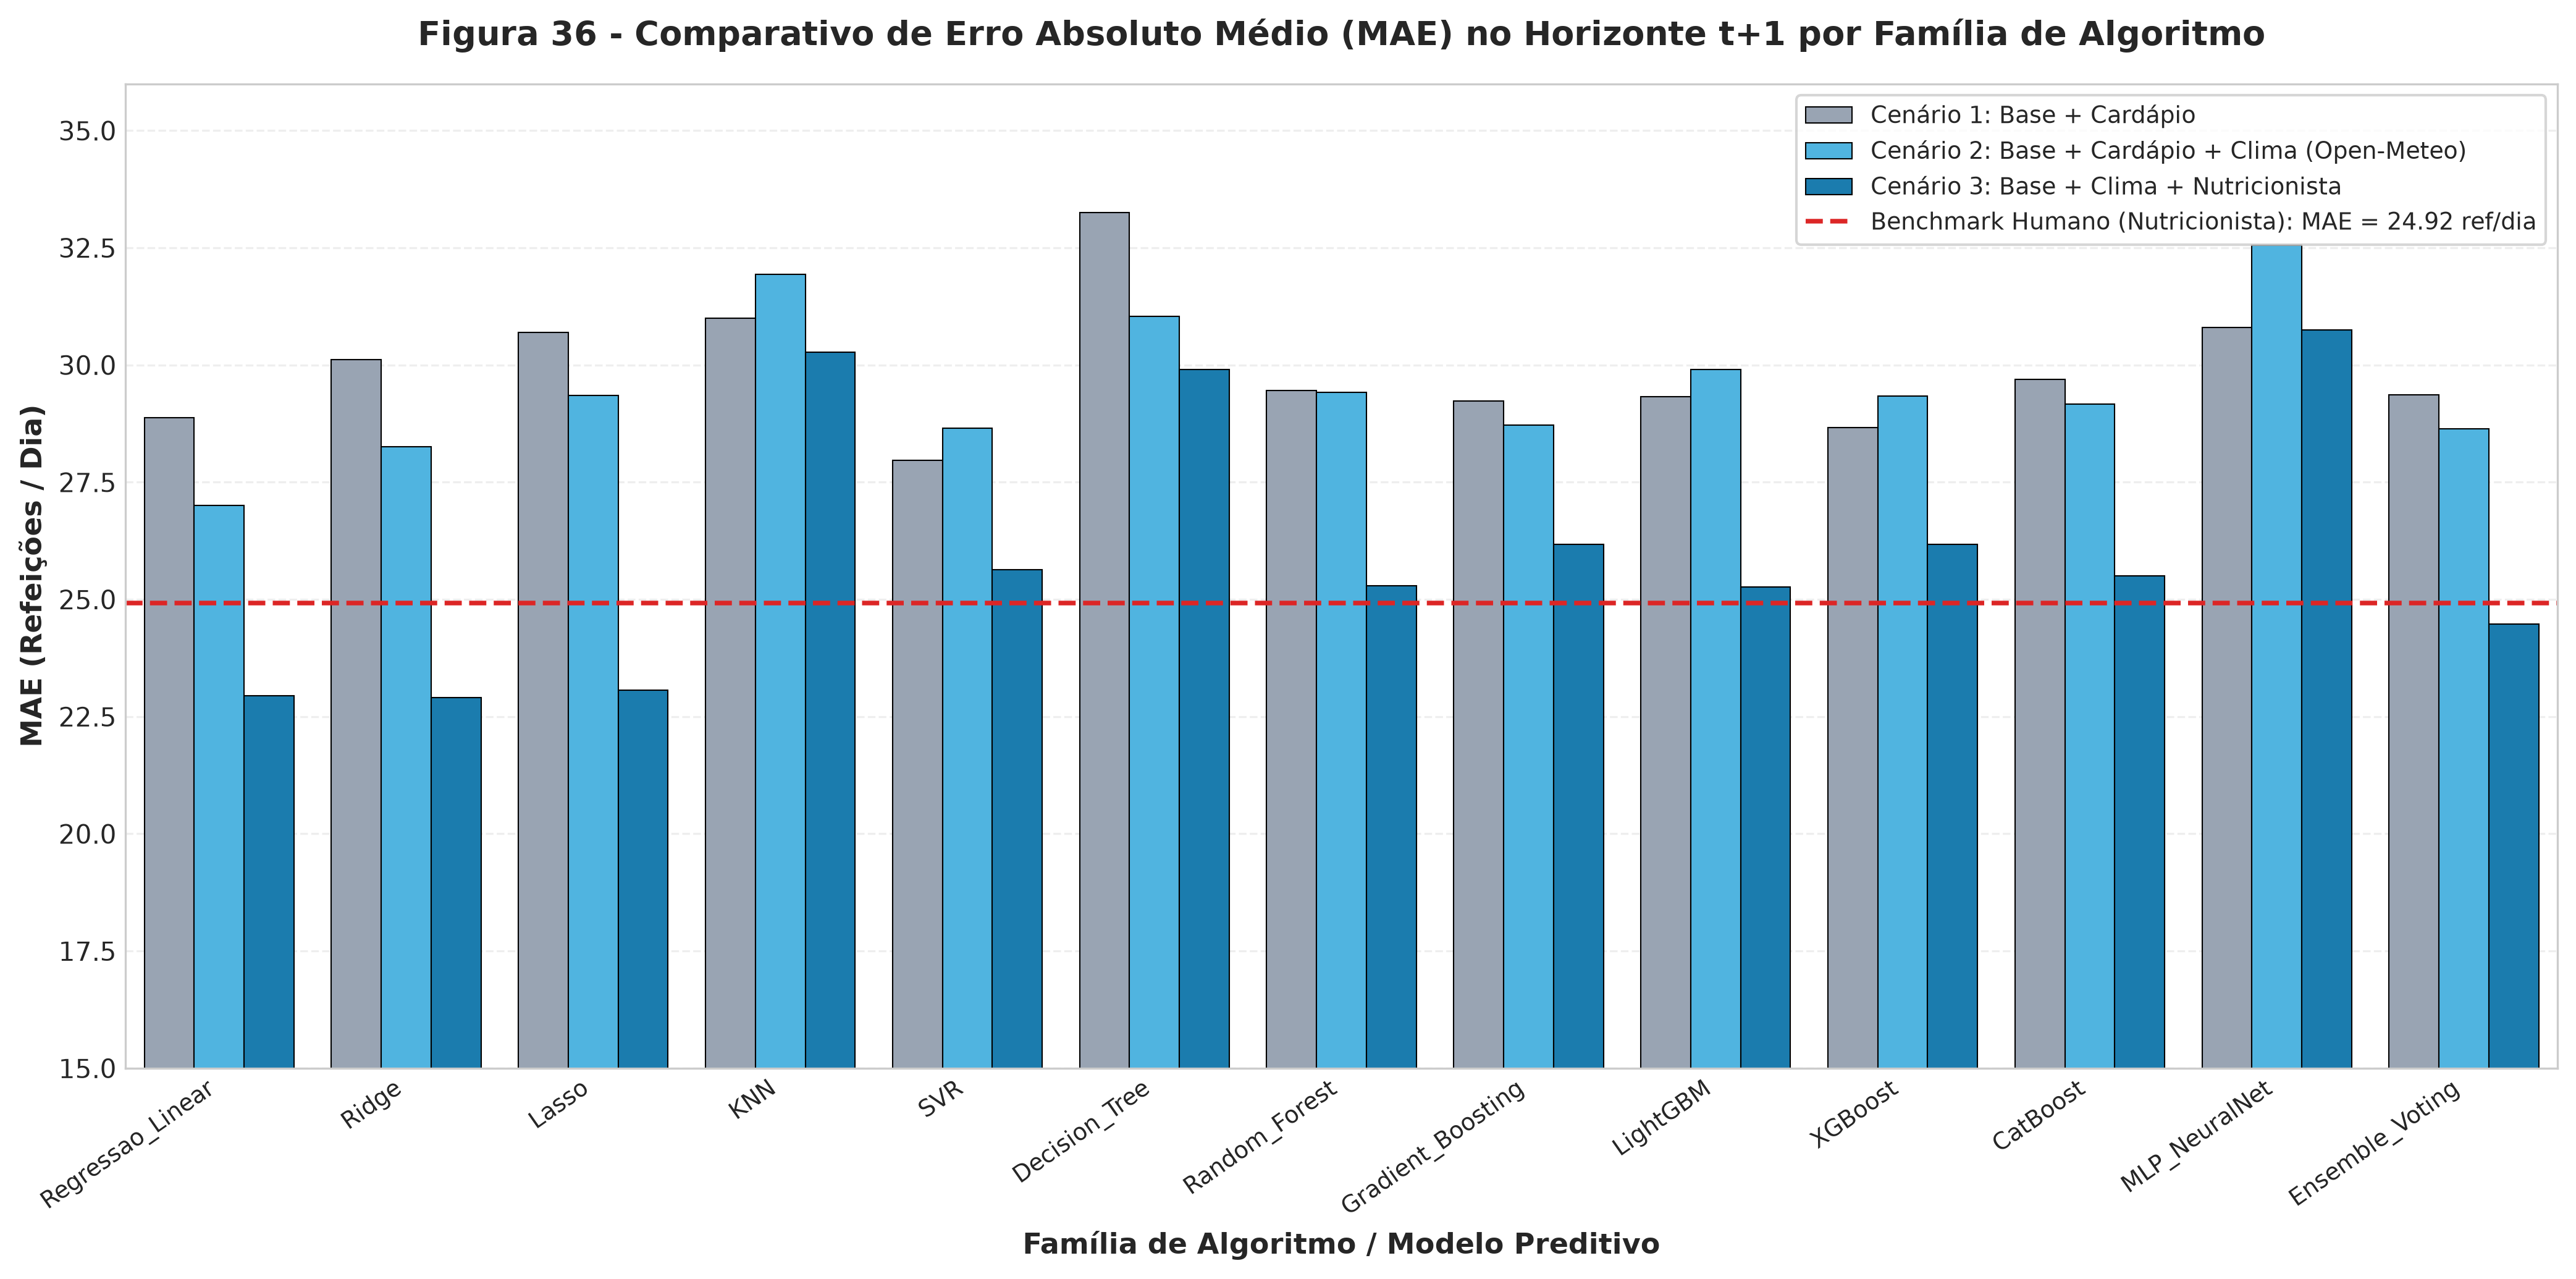

[OK] Figura salva em: ../reports/figuras/fig36_comparativo_mae_rmse_cenarios.png


In [2]:
df_t1 = df_met[df_met["horizonte"].str.contains("Semana_t1")].copy()

# Selecionar principais modelos representativos
modelos_destaque = [
    "Regressao_Linear", "Ridge", "Lasso", "KNN", "SVR",
    "Decision_Tree", "Random_Forest", "Gradient_Boosting",
    "LightGBM", "XGBoost", "CatBoost", "MLP_NeuralNet", "Ensemble_Voting"
]
df_t1_sub = df_t1[df_t1["algoritmo"].isin(modelos_destaque)].copy()

fig, ax = plt.subplots(figsize=(14, 7), dpi=300)

palette = {"Cenario_1_Base_Cardapio": "#94a3b8", "Cenario_2_Com_Clima": "#38bdf8", "Cenario_3_Com_Nutricionista": "#0284c7"}
labels_legenda = {
    "Cenario_1_Base_Cardapio": "Cenário 1: Base + Cardápio",
    "Cenario_2_Com_Clima": "Cenário 2: Base + Cardápio + Clima (Open-Meteo)",
    "Cenario_3_Com_Nutricionista": "Cenário 3: Base + Clima + Nutricionista"
}

sns.barplot(
    data=df_t1_sub,
    x="algoritmo",
    y="mae",
    hue="cenario",
    palette=palette,
    ax=ax,
    edgecolor="black",
    linewidth=0.5
)

# Linha de benchmark da nutricionista pura
mae_humano = df_met[df_met["algoritmo"] == "Estimativa_Nutricionista_Pura"]["mae"].values[0]
ax.axhline(mae_humano, color="#dc2626", linestyle="--", linewidth=1.8, label=f"Benchmark Humano (Nutricionista): MAE = {mae_humano:.2f} ref/dia")

ax.set_title("Figura 36 - Comparativo de Erro Absoluto Médio (MAE) no Horizonte t+1 por Família de Algoritmo", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Família de Algoritmo / Modelo Preditivo", fontsize=11, fontweight="bold")
ax.set_ylabel("MAE (Refeições / Dia)", fontsize=11, fontweight="bold")
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
ax.set_ylim(15, 36)

# Atualizar legenda
handles, labels = ax.get_legend_handles_labels()
labels = [labels_legenda.get(l, l) for l in labels]
ax.legend(handles=handles, labels=labels, loc="upper right", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=9)

plt.tight_layout()
fig_path = f"{FIG_DIR}/fig36_comparativo_mae_rmse_cenarios.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 3. Coeficiente de Determinação ($R^2$) e WAPE (%)
Avaliação da variância explicada ($R^2$) e do erro percentual ponderado (WAPE) para atestar a robustez dos modelos.


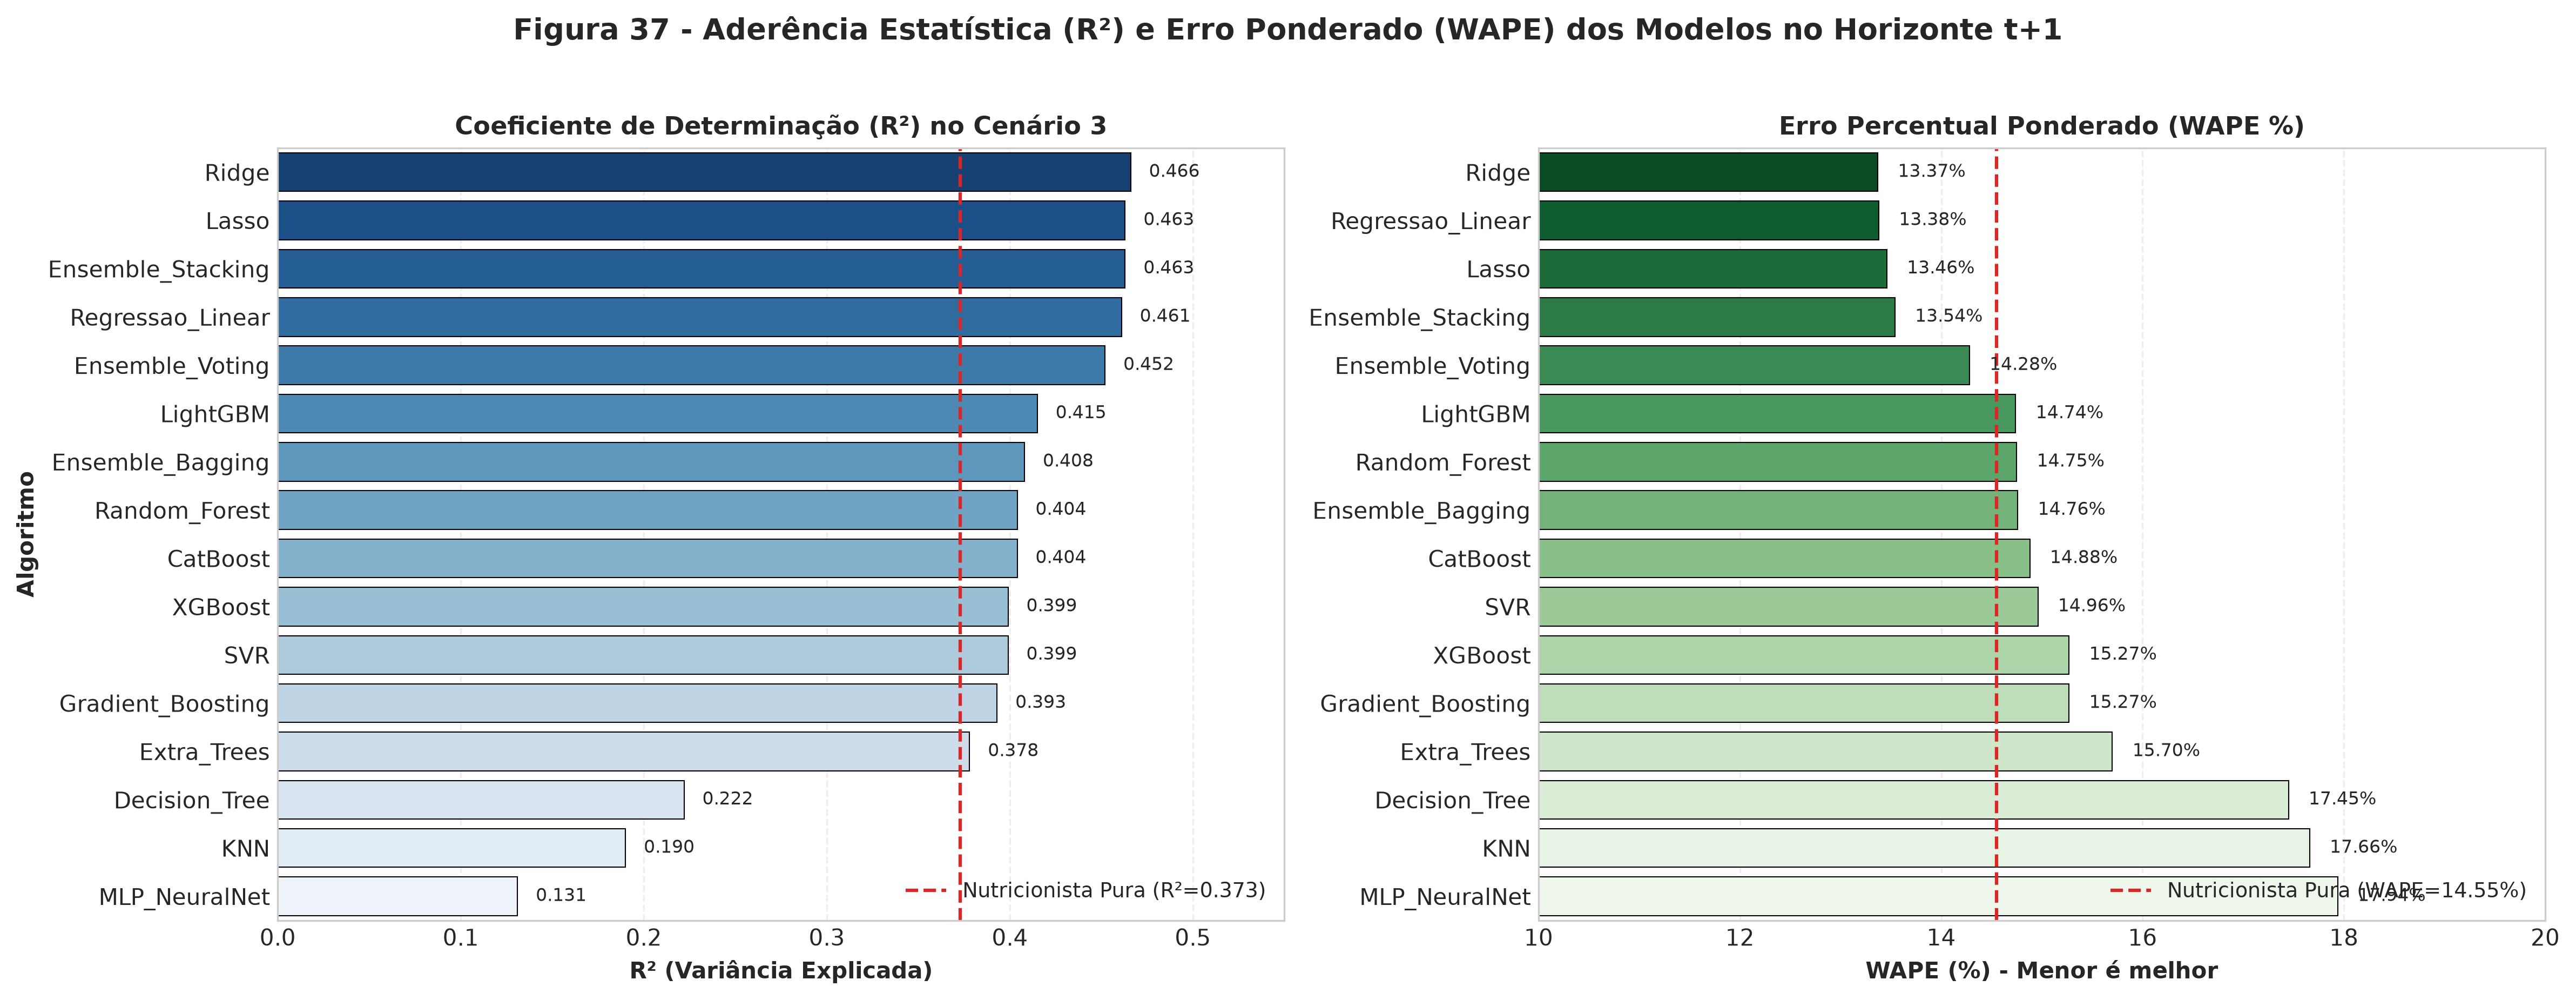

[OK] Figura salva em: ../reports/figuras/fig37_comparativo_r2_wape_cenarios.png


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

# 1. R² no Cenário 3 (Com Nutricionista)
df_c3 = df_met[(df_met["cenario"] == "Cenario_3_Com_Nutricionista") & (df_met["horizonte"].str.contains("Semana_t1"))].copy()
df_c3 = df_c3.sort_values("r2", ascending=False)

sns.barplot(data=df_c3, x="r2", y="algoritmo", palette="Blues_r", ax=ax1, edgecolor="black", linewidth=0.5)
r2_humano = df_met[df_met["algoritmo"] == "Estimativa_Nutricionista_Pura"]["r2"].values[0]
ax1.axvline(r2_humano, color="#dc2626", linestyle="--", linewidth=1.5, label=f"Nutricionista Pura (R²={r2_humano:.3f})")
ax1.set_title("Coeficiente de Determinação (R²) no Cenário 3", fontsize=11, fontweight="bold")
ax1.set_xlabel("R² (Variância Explicada)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Algoritmo", fontsize=10, fontweight="bold")
ax1.legend(loc="lower right", fontsize=9)
ax1.set_xlim(0, 0.55)

for p in ax1.patches:
    ax1.annotate(f"{p.get_width():.3f}", (p.get_width() + 0.01, p.get_y() + p.get_height()/2.),
                 va='center', fontsize=8)

# 2. WAPE (%) no Cenário 3
df_c3_wape = df_c3.sort_values("wape_pct", ascending=True)
sns.barplot(data=df_c3_wape, x="wape_pct", y="algoritmo", palette="Greens_r", ax=ax2, edgecolor="black", linewidth=0.5)
wape_humano = df_met[df_met["algoritmo"] == "Estimativa_Nutricionista_Pura"]["wape_pct"].values[0]
ax2.axvline(wape_humano, color="#dc2626", linestyle="--", linewidth=1.5, label=f"Nutricionista Pura (WAPE={wape_humano:.2f}%)")
ax2.set_title("Erro Percentual Ponderado (WAPE %)", fontsize=11, fontweight="bold")
ax2.set_xlabel("WAPE (%) - Menor é melhor", fontsize=10, fontweight="bold")
ax2.set_ylabel("", fontsize=10)
ax2.legend(loc="lower right", fontsize=9)
ax2.set_xlim(10, 20)

for p in ax2.patches:
    ax2.annotate(f"{p.get_width():.2f}%", (p.get_width() + 0.2, p.get_y() + p.get_height()/2.),
                 va='center', fontsize=8)

plt.suptitle("Figura 37 - Aderência Estatística (R²) e Erro Ponderado (WAPE) dos Modelos no Horizonte t+1", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = f"{FIG_DIR}/fig37_comparativo_r2_wape_cenarios.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 4. Balanço Operacional de Sobras vs. Faltas
O gráfico operacional de maior relevância para a tomada de decisão da gestão pública:
- A estimativa humana pura da nutricionista adota o princípio da precaução e acumula **2.705 refeições de sobra** com 684 refeições de falta.
- Os modelos de machine learning (especialmente XGBoost, Random Forest, Ridge e Lasso) reduzem as sobras em mais de **60%**, atingindo a zona de equilíbrio ótimo.


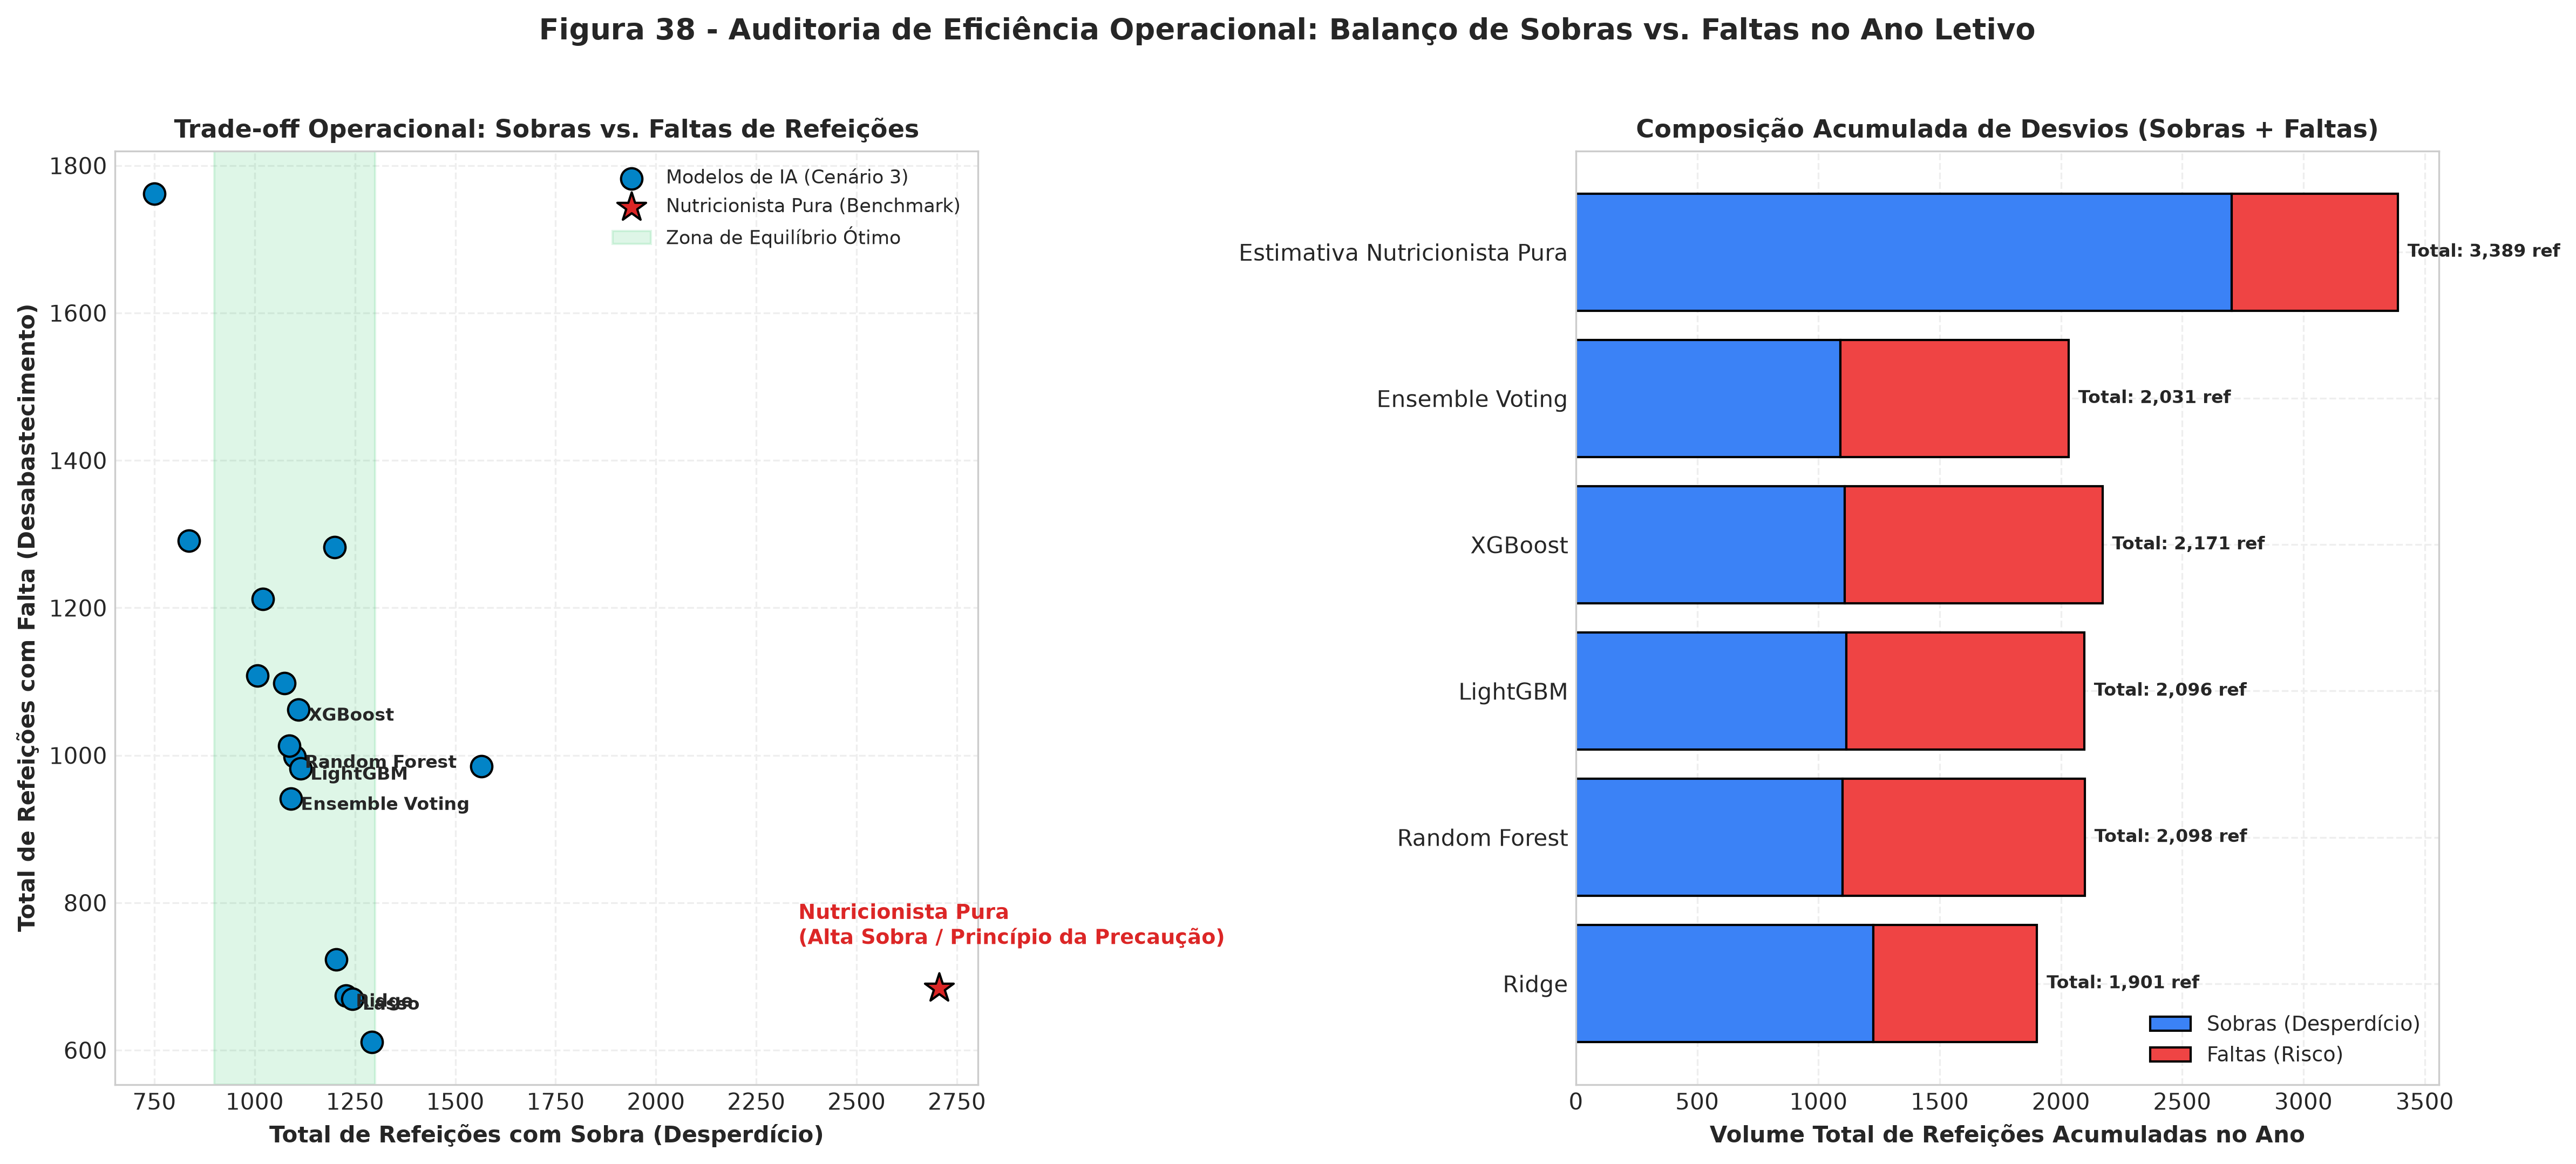

[OK] Figura salva em: ../reports/figuras/fig38_balanco_sobra_falta_modelos.png


In [4]:
df_c3_balanco = df_met[(df_met["cenario"] == "Cenario_3_Com_Nutricionista") & (df_met["horizonte"].str.contains("Semana_t1"))].copy()
row_humano = df_met[df_met["algoritmo"] == "Estimativa_Nutricionista_Pura"].iloc[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), dpi=300)

# Gráfico 1: Dispersão 2D (Trade-off de Sobras vs Faltas)
ax1.scatter(df_c3_balanco["total_sobra_ref"], df_c3_balanco["total_falta_ref"], color="#0284c7", s=90, edgecolors="black", zorder=3, label="Modelos de IA (Cenário 3)")
ax1.scatter([row_humano["total_sobra_ref"]], [row_humano["total_falta_ref"]], color="#dc2626", s=180, edgecolors="black", marker="*", zorder=4, label="Nutricionista Pura (Benchmark)")

for _, r in df_c3_balanco.iterrows():
    if r["algoritmo"] in ["Ridge", "Lasso", "XGBoost", "Random_Forest", "LightGBM", "Ensemble_Voting"]:
        ax1.annotate(r["algoritmo"].replace("_", " "), (r["total_sobra_ref"]+25, r["total_falta_ref"]-15), fontsize=8, fontweight="bold")
ax1.annotate("Nutricionista Pura\n(Alta Sobra / Princípio da Precaução)", (row_humano["total_sobra_ref"]-350, row_humano["total_falta_ref"]+60), fontsize=9, fontweight="bold", color="#dc2626")

ax1.axvspan(900, 1300, color="#22c55e", alpha=0.15, label="Zona de Equilíbrio Ótimo")
ax1.set_title("Trade-off Operacional: Sobras vs. Faltas de Refeições", fontsize=11, fontweight="bold")
ax1.set_xlabel("Total de Refeições com Sobra (Desperdício)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Total de Refeições com Falta (Desabastecimento)", fontsize=10, fontweight="bold")
ax1.legend(loc="upper right", fontsize=8.5)

# Gráfico 2: Barras Empilhadas de Composição Total
dados_plot = df_c3_balanco[df_c3_balanco["algoritmo"].isin(["Ridge", "XGBoost", "Random_Forest", "LightGBM", "Ensemble_Voting"])].copy()
dados_plot = pd.concat([dados_plot, pd.DataFrame([row_humano])], ignore_index=True)

y_pos = np.arange(len(dados_plot))
ax2.barh(y_pos, dados_plot["total_sobra_ref"], color="#3b82f6", edgecolor="black", label="Sobras (Desperdício)")
ax2.barh(y_pos, dados_plot["total_falta_ref"], left=dados_plot["total_sobra_ref"], color="#ef4444", edgecolor="black", label="Faltas (Risco)")
ax2.set_yticks(y_pos)
ax2.set_yticklabels(dados_plot["algoritmo"].str.replace("_", " "))
ax2.set_xlabel("Volume Total de Refeições Acumuladas no Ano", fontsize=10, fontweight="bold")
ax2.set_title("Composição Acumulada de Desvios (Sobras + Faltas)", fontsize=11, fontweight="bold")
ax2.legend(loc="lower right", fontsize=9)

for idx, r in dados_plot.iterrows():
    tot = r["total_sobra_ref"] + r["total_falta_ref"]
    ax2.annotate(f"Total: {tot:,.0f} ref", (tot + 40, idx), va="center", fontsize=8, fontweight="bold")

plt.suptitle("Figura 38 - Auditoria de Eficiência Operacional: Balanço de Sobras vs. Faltas no Ano Letivo", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = f"{FIG_DIR}/fig38_balanco_sobra_falta_modelos.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 5. Impacto Preditivo da API de Meteorologia no Horizonte $t+2$ (Longo Prazo)
No horizonte de 2 semanas de antecedência, onde **não existem reservas humanas**, a previsão depende exclusivamente do calendário, cardápio e meteorologia.
O gráfico comprova a redução de erro proporcionada pela integração da API Open-Meteo.


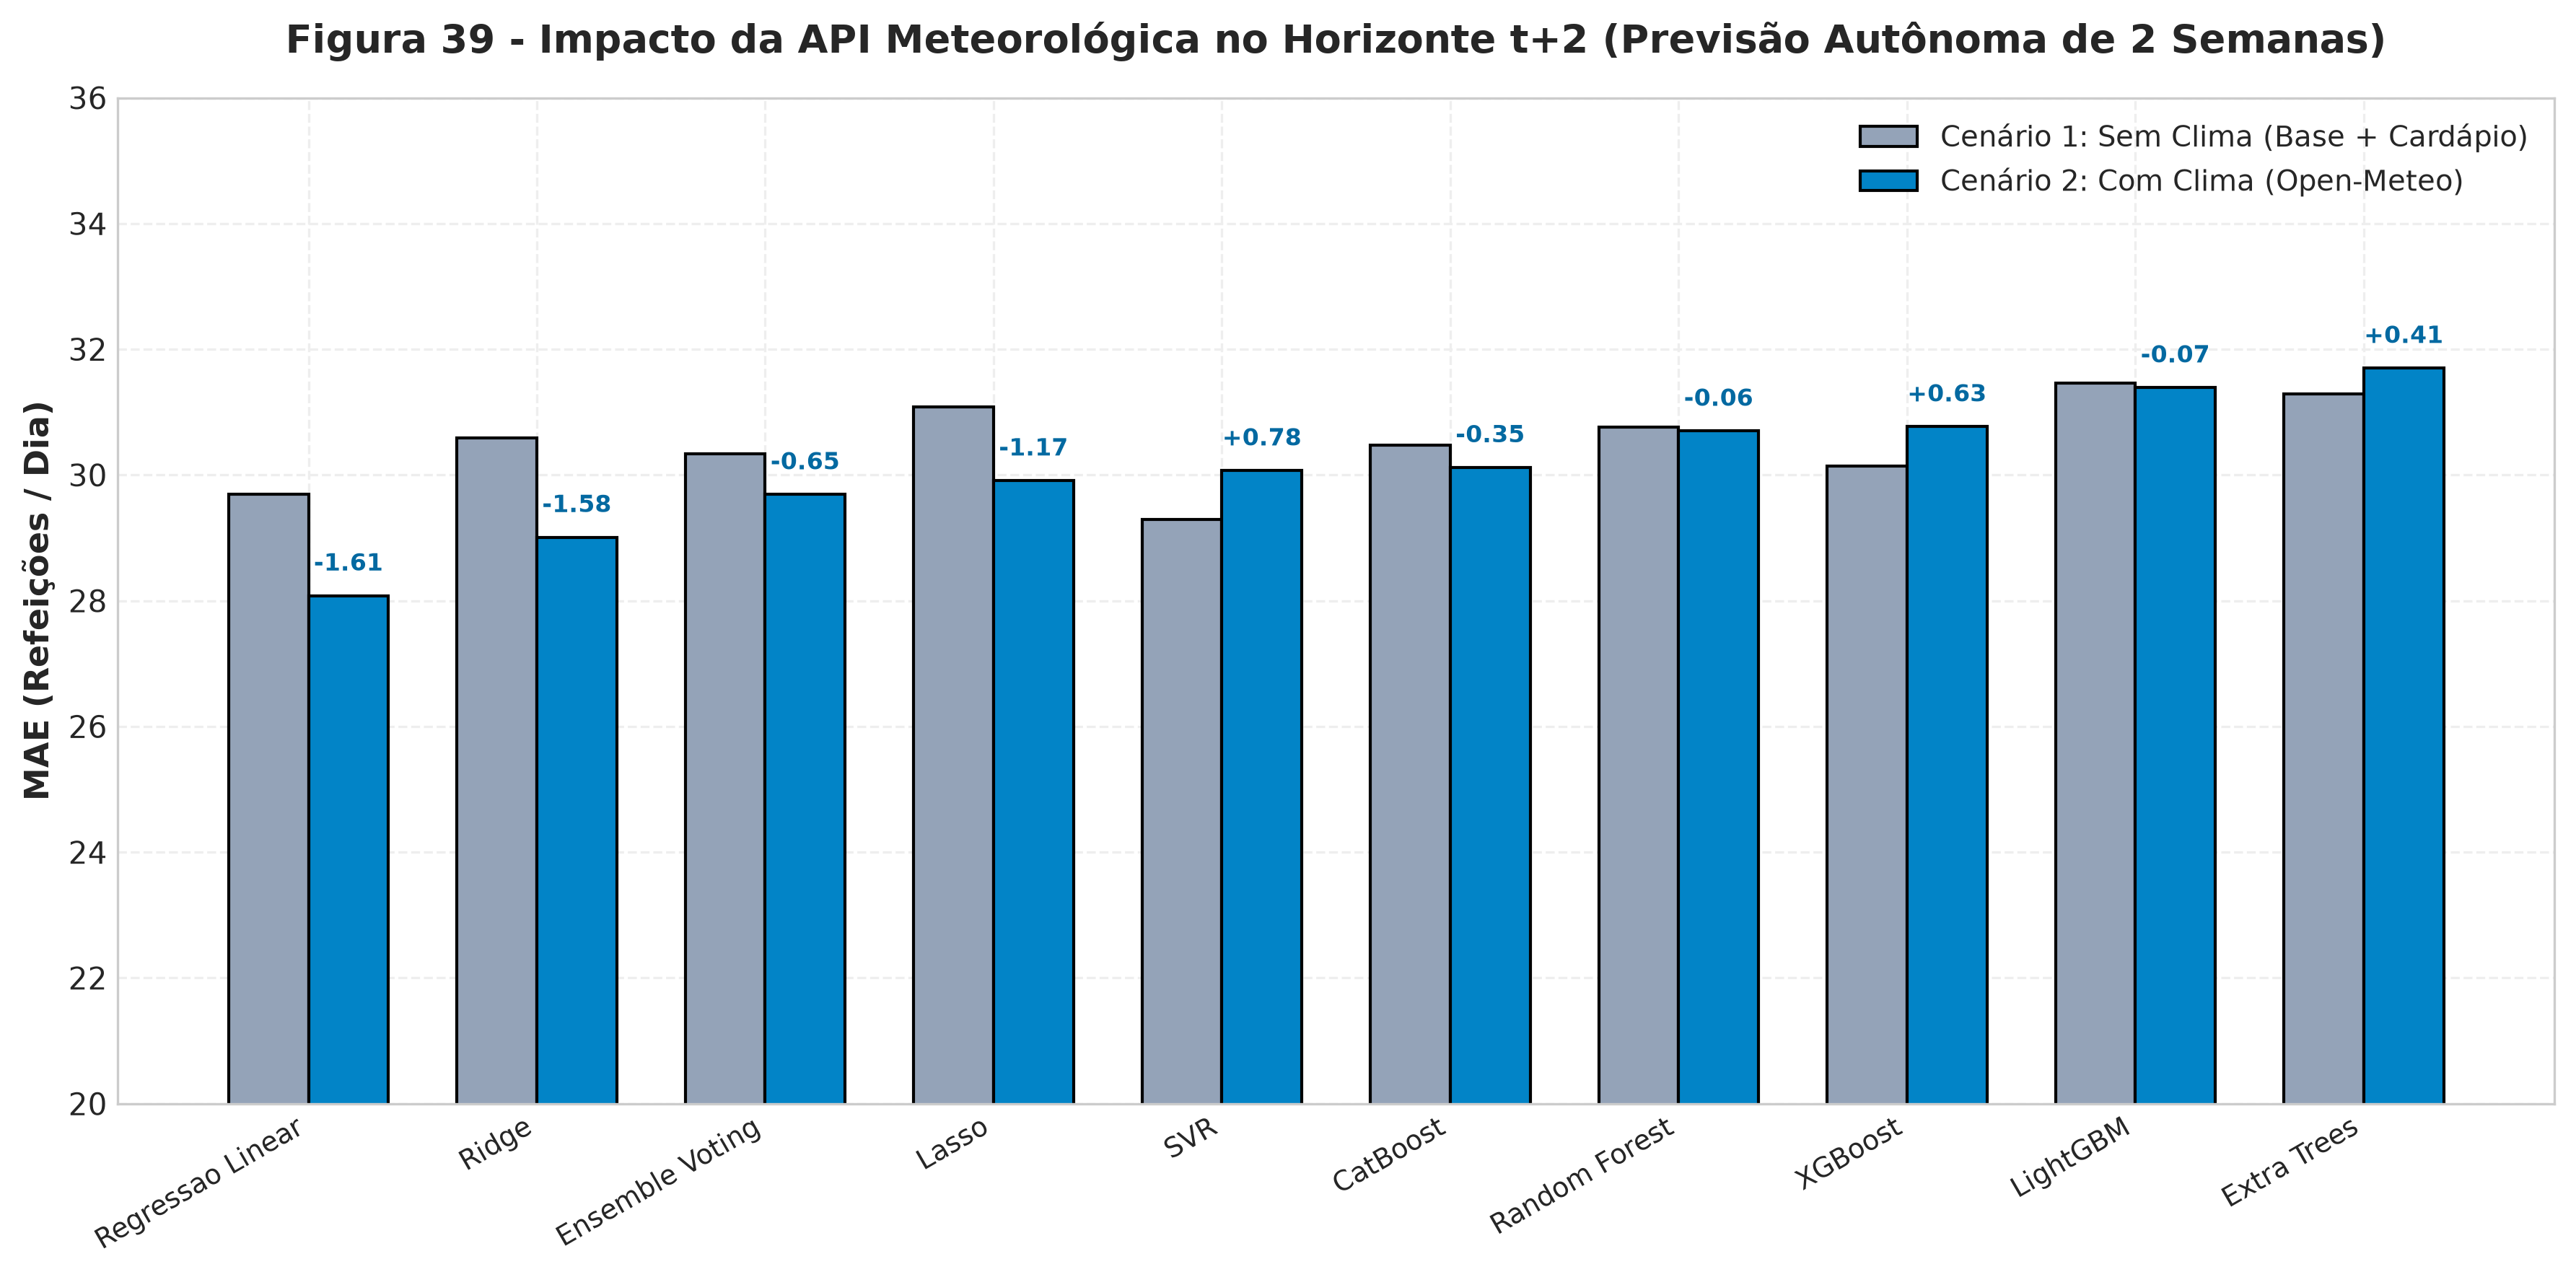

[OK] Figura salva em: ../reports/figuras/fig39_impacto_clima_horizonte_t2.png


In [5]:
df_t2 = df_met[df_met["horizonte"].str.contains("Semana_t2")].copy()
pivot_t2 = df_t2.pivot(index="algoritmo", columns="cenario", values="mae").dropna()

# Filtrar principais modelos
modelos_t2 = ["Regressao_Linear", "Ridge", "Lasso", "SVR", "Random_Forest", "Extra_Trees", "LightGBM", "XGBoost", "CatBoost", "Ensemble_Voting"]
pivot_t2 = pivot_t2.loc[pivot_t2.index.isin(modelos_t2)]
pivot_t2["reducao_erro"] = pivot_t2["Cenario_1_Base_Cardapio"] - pivot_t2["Cenario_2_Com_Clima"]
pivot_t2 = pivot_t2.sort_values("Cenario_2_Com_Clima", ascending=True)

fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

x = np.arange(len(pivot_t2))
w = 0.35

ax.bar(x - w/2, pivot_t2["Cenario_1_Base_Cardapio"], width=w, label="Cenário 1: Sem Clima (Base + Cardápio)", color="#94a3b8", edgecolor="black")
ax.bar(x + w/2, pivot_t2["Cenario_2_Com_Clima"], width=w, label="Cenário 2: Com Clima (Open-Meteo)", color="#0284c7", edgecolor="black")

ax.set_xticks(x)
ax.set_xticklabels(pivot_t2.index.str.replace("_", " "), rotation=30, ha="right", fontsize=9)
ax.set_ylabel("MAE (Refeições / Dia)", fontsize=11, fontweight="bold")
ax.set_title("Figura 39 - Impacto da API Meteorológica no Horizonte t+2 (Previsão Autônoma de 2 Semanas)", fontsize=13, fontweight="bold", pad=15)
ax.set_ylim(20, 36)
ax.legend(loc="upper right", fontsize=9.5)

# Anotar ganho
for i, (_, row) in enumerate(pivot_t2.iterrows()):
    ganho = row["reducao_erro"]
    sinal = "-" if ganho > 0 else "+"
    ax.annotate(f"{sinal}{abs(ganho):.2f}", (i + w/2, row["Cenario_2_Com_Clima"] + 0.4),
                ha="center", fontsize=8, fontweight="bold", color="#0369a1")

plt.tight_layout()
fig_path = f"{FIG_DIR}/fig39_impacto_clima_horizonte_t2.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 6. Ganho do Mecanismo de Re-forecast ($t+2 \rightarrow t+1$)
Mensuração empírica do valor operacional gerado quando a semana transiciona de $t+2$ para $t+1$, recebendo a estimativa da nutricionista na sexta-feira intermediária.


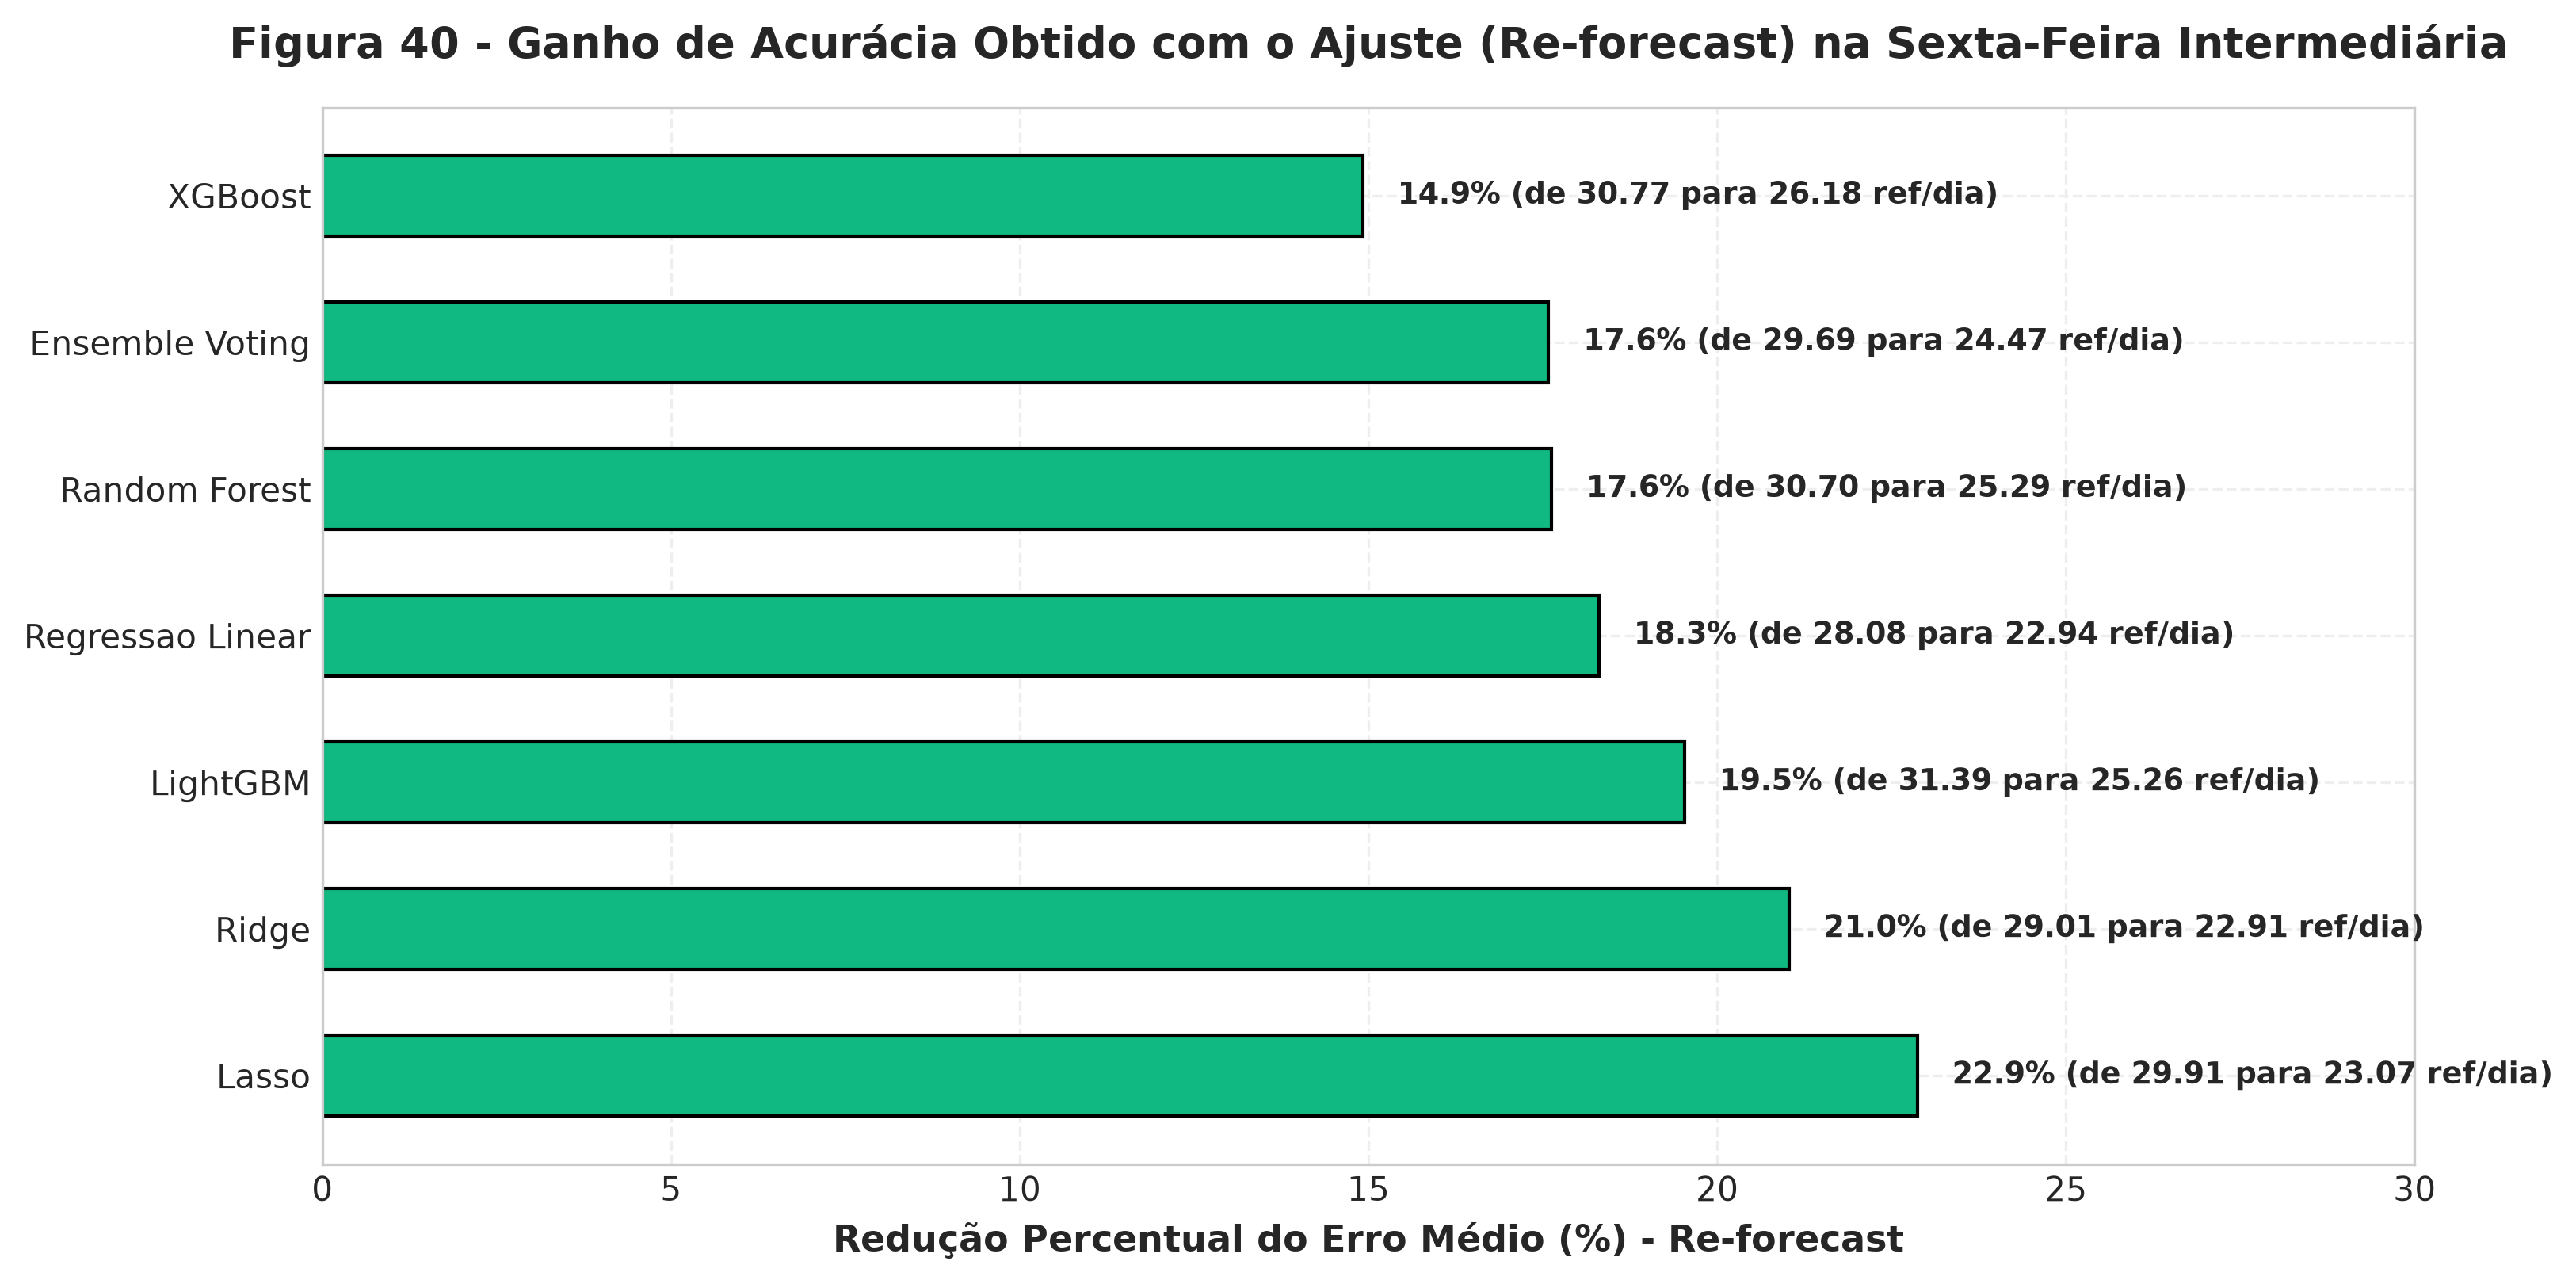

[OK] Figura salva em: ../reports/figuras/fig40_ganho_reforecast_t2_para_t1.png


In [6]:
algos_reforecast = ["Ridge", "Lasso", "Regressao_Linear", "XGBoost", "LightGBM", "Random_Forest", "Ensemble_Voting"]

t2_erros = df_met[(df_met["cenario"] == "Cenario_2_Com_Clima") & (df_met["horizonte"].str.contains("Semana_t2")) & (df_met["algoritmo"].isin(algos_reforecast))].set_index("algoritmo")["mae"]
t1_erros = df_met[(df_met["cenario"] == "Cenario_3_Com_Nutricionista") & (df_met["horizonte"].str.contains("Semana_t1")) & (df_met["algoritmo"].isin(algos_reforecast))].set_index("algoritmo")["mae"]

df_reforecast = pd.DataFrame({"MAE_t2": t2_erros, "MAE_t1": t1_erros}).dropna()
df_reforecast["ganho_pct"] = ((df_reforecast["MAE_t2"] - df_reforecast["MAE_t1"]) / df_reforecast["MAE_t2"]) * 100.0
df_reforecast = df_reforecast.sort_values("ganho_pct", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)

y_pos = np.arange(len(df_reforecast))
ax.barh(y_pos, df_reforecast["ganho_pct"], color="#10b981", edgecolor="black", height=0.55)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_reforecast.index.str.replace("_", " "), fontsize=10)
ax.set_xlabel("Redução Percentual do Erro Médio (%) - Re-forecast", fontsize=11, fontweight="bold")
ax.set_title("Figura 40 - Ganho de Acurácia Obtido com o Ajuste (Re-forecast) na Sexta-Feira Intermediária", fontsize=13, fontweight="bold", pad=15)
ax.set_xlim(0, 30)

for idx, r in df_reforecast.iterrows():
    ax.annotate(f"{r['ganho_pct']:.1f}% (de {r['MAE_t2']:.2f} para {r['MAE_t1']:.2f} ref/dia)",
                (r["ganho_pct"] + 0.5, df_reforecast.index.get_loc(idx)),
                va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig_path = f"{FIG_DIR}/fig40_ganho_reforecast_t2_para_t1.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 7. Análise Histórica: Reserva dos Alunos (2023–2025) vs. Quantitativo da Nutricionista (2026)
Confronto da série temporal completa de 2023 a 2026:
- **2023 a 2025:** Regime de "reserva dos alunos" — os alunos subestimavam sistematicamente o comparecimento, gerando picos crônicos de falta.
- **2026:** Regime de "quantitativo institucional da nutricionista" — superdimensionamento prudencial para garantir segurança alimentar, gerando sobras elevadas.


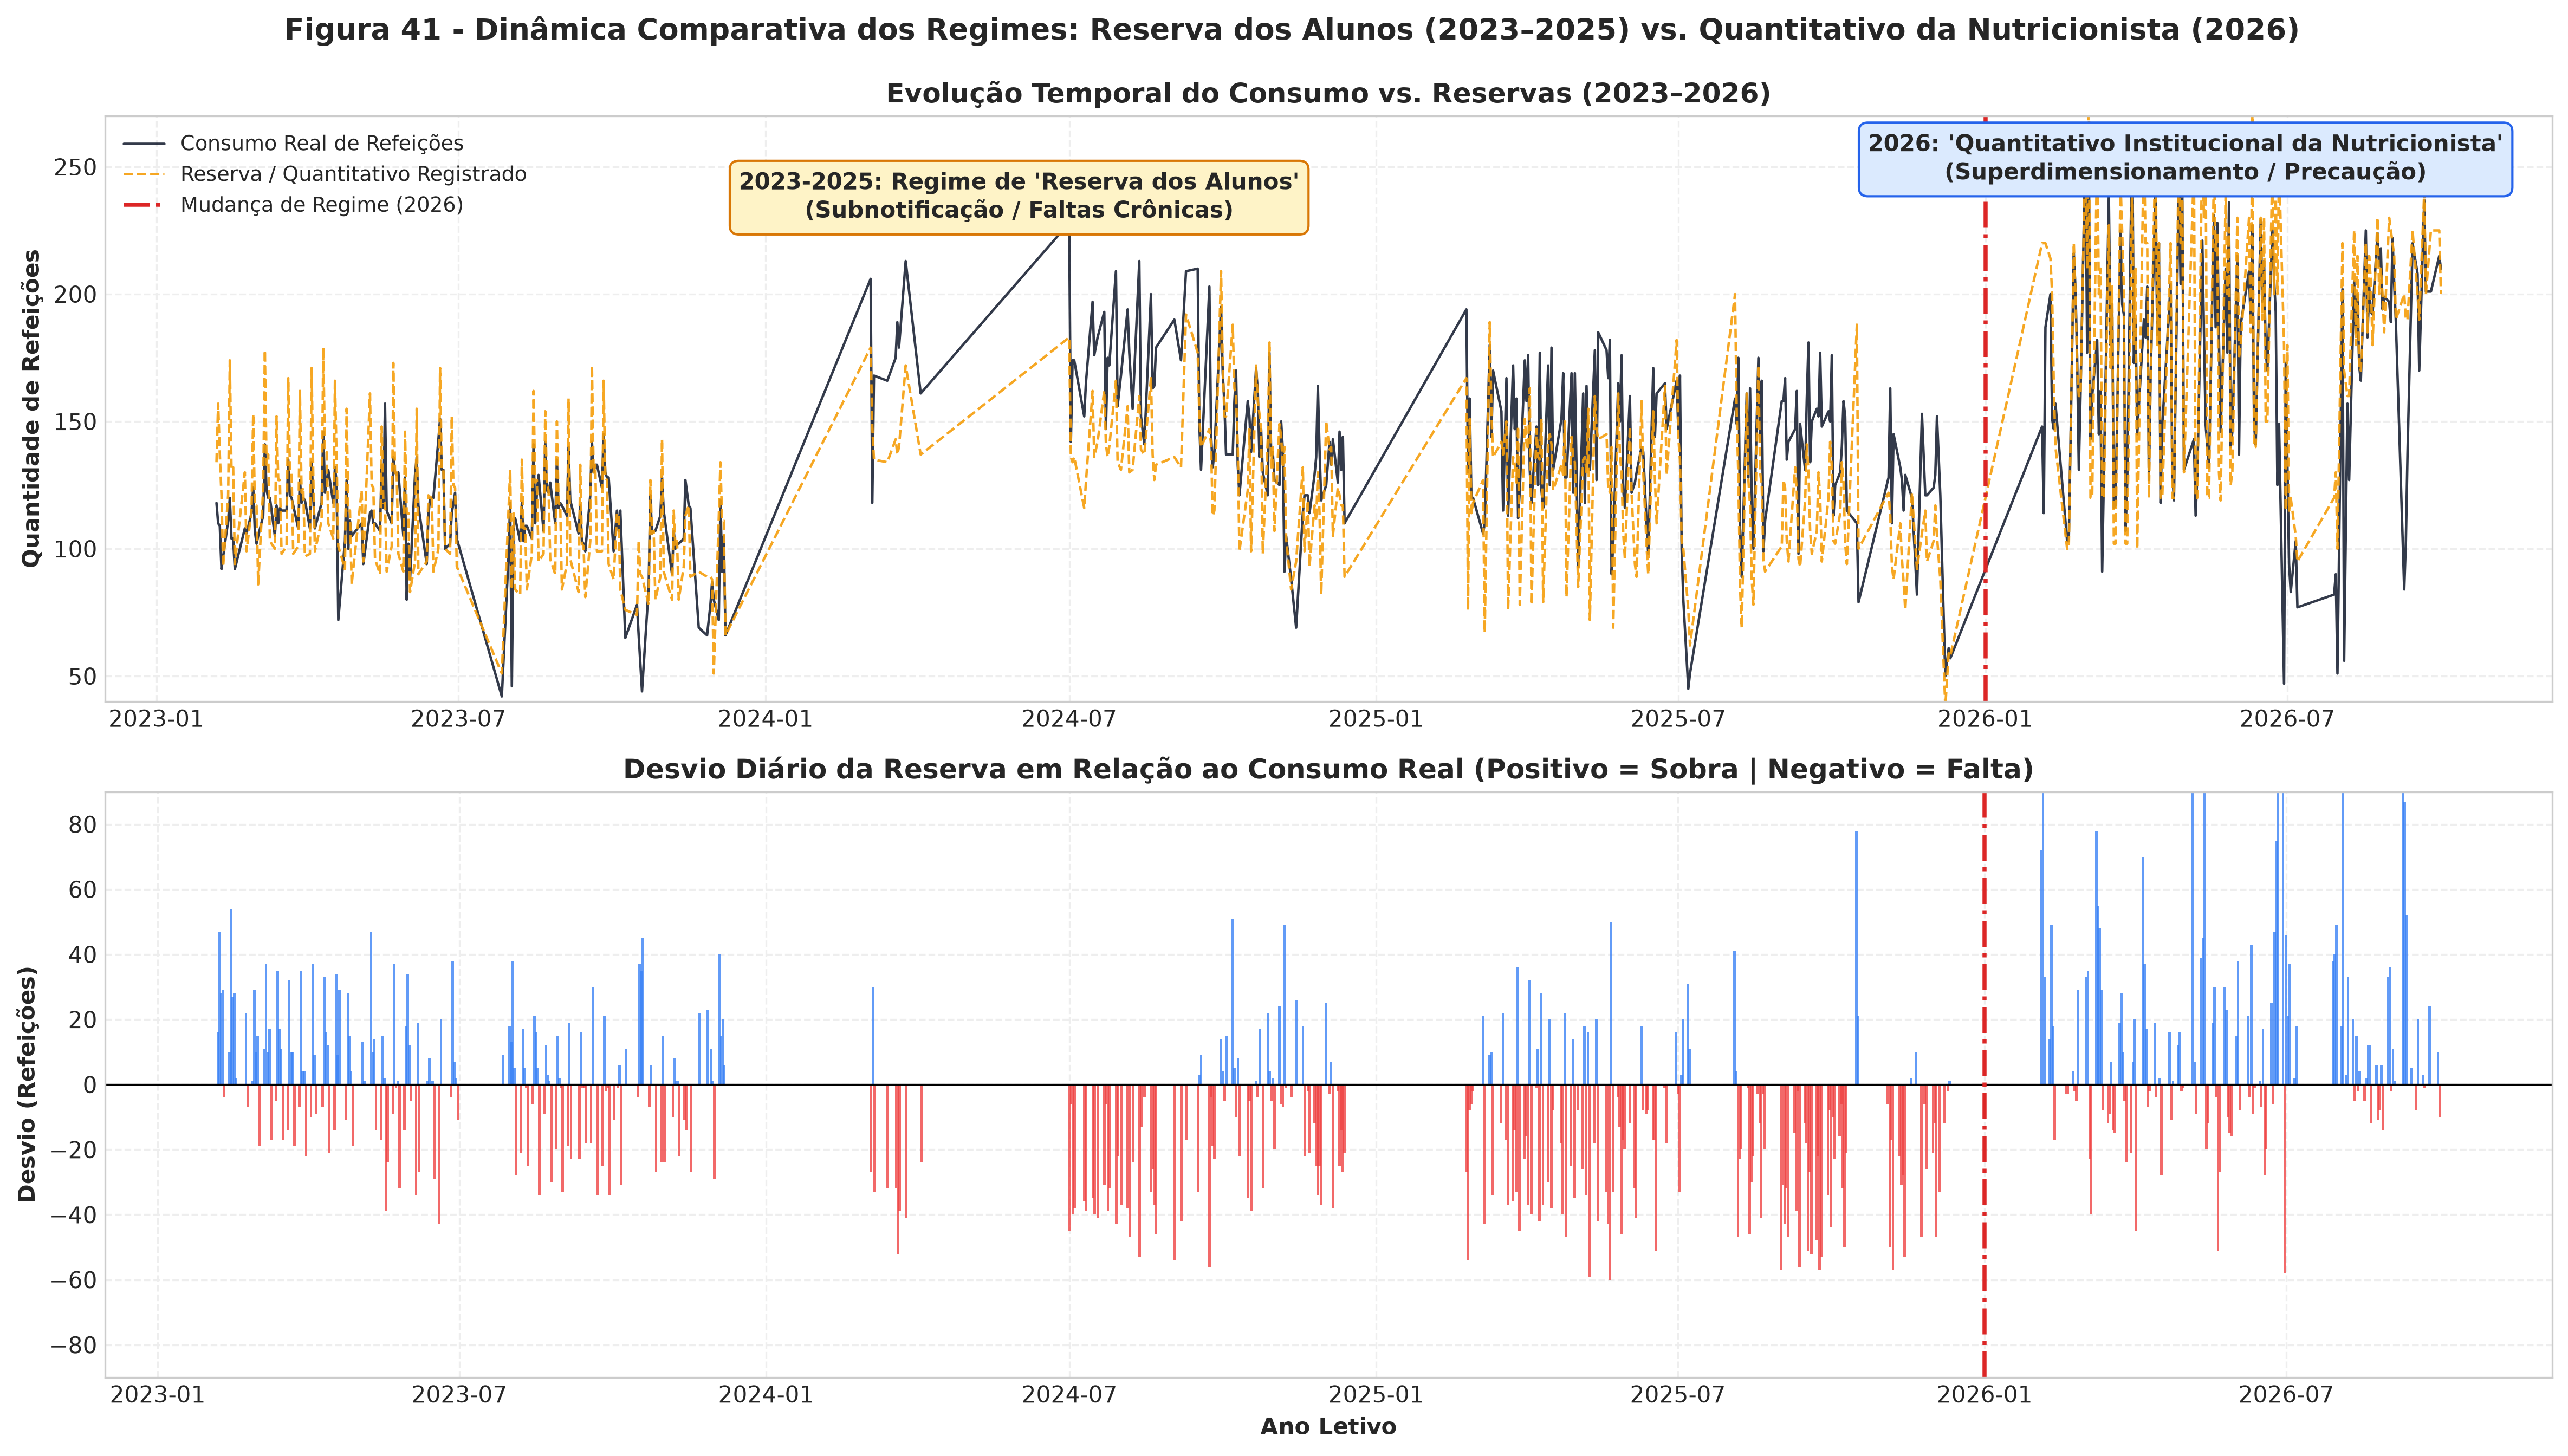

[OK] Figura salva em: ../reports/figuras/fig41_evolucao_temporal_regimes_reserva.png


In [7]:
df_valid = df_gold[df_gold["consumo"].notna() & df_gold["reservas"].notna()].sort_values("data_dt").copy()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), dpi=300, sharex=False)

# Subplot 1: Série Temporal Contínua
ax1.plot(df_valid["data_dt"], df_valid["consumo"], color="#0f172a", linewidth=1.1, label="Consumo Real de Refeições", alpha=0.85)
ax1.plot(df_valid["data_dt"], df_valid["reservas"], color="#f59e0b", linewidth=1.1, linestyle="--", label="Reserva / Quantitativo Registrado", alpha=0.9)

# Linha divisória da mudança de regime
data_corte_regime = pd.to_datetime("2026-01-01")
ax1.axvline(data_corte_regime, color="#dc2626", linestyle="-.", linewidth=1.8, label="Mudança de Regime (2026)")

ax1.annotate("2023-2025: Regime de 'Reserva dos Alunos'\n(Subnotificação / Faltas Crônicas)",
             (pd.to_datetime("2024-06-01"), 230), ha="center", fontsize=10, fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.4", fc="#fef3c7", ec="#d97706"))

ax1.annotate("2026: 'Quantitativo Institucional da Nutricionista'\n(Superdimensionamento / Precaução)",
             (pd.to_datetime("2026-05-01"), 245), ha="center", fontsize=10, fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.4", fc="#dbeafe", ec="#2563eb"))

ax1.set_title("Evolução Temporal do Consumo vs. Reservas (2023–2026)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Quantidade de Refeições", fontsize=10, fontweight="bold")
ax1.legend(loc="upper left", fontsize=9)
ax1.set_ylim(40, 270)

# Subplot 2: Resíduo Diário (Reserva - Consumo)
df_valid["residuo_reserva"] = df_valid["reservas"] - df_valid["consumo"]
cores_residuo = np.where(df_valid["residuo_reserva"] >= 0, "#3b82f6", "#ef4444")

ax2.bar(df_valid["data_dt"], df_valid["residuo_reserva"], color=cores_residuo, width=1.5, alpha=0.8)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.axvline(data_corte_regime, color="#dc2626", linestyle="-.", linewidth=1.8)

ax2.set_title("Desvio Diário da Reserva em Relação ao Consumo Real (Positivo = Sobra | Negativo = Falta)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Desvio (Refeições)", fontsize=10, fontweight="bold")
ax2.set_xlabel("Ano Letivo", fontsize=10, fontweight="bold")
ax2.set_ylim(-90, 90)

plt.suptitle("Figura 41 - Dinâmica Comparativa dos Regimes: Reserva dos Alunos (2023–2025) vs. Quantitativo da Nutricionista (2026)", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
fig_path = f"{FIG_DIR}/fig41_evolucao_temporal_regimes_reserva.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 8. Curva de Teste Walk-Forward em 2026: Consumo Real vs. Modelos
Visualização contínua das sextas-feiras de teste em 2026 comparando:
- Consumo Real
- Estimativa da Nutricionista Pura
- Melhor Modelo Linear (Ridge)
- Melhor Modelo Baseado em Árvore (XGBoost)


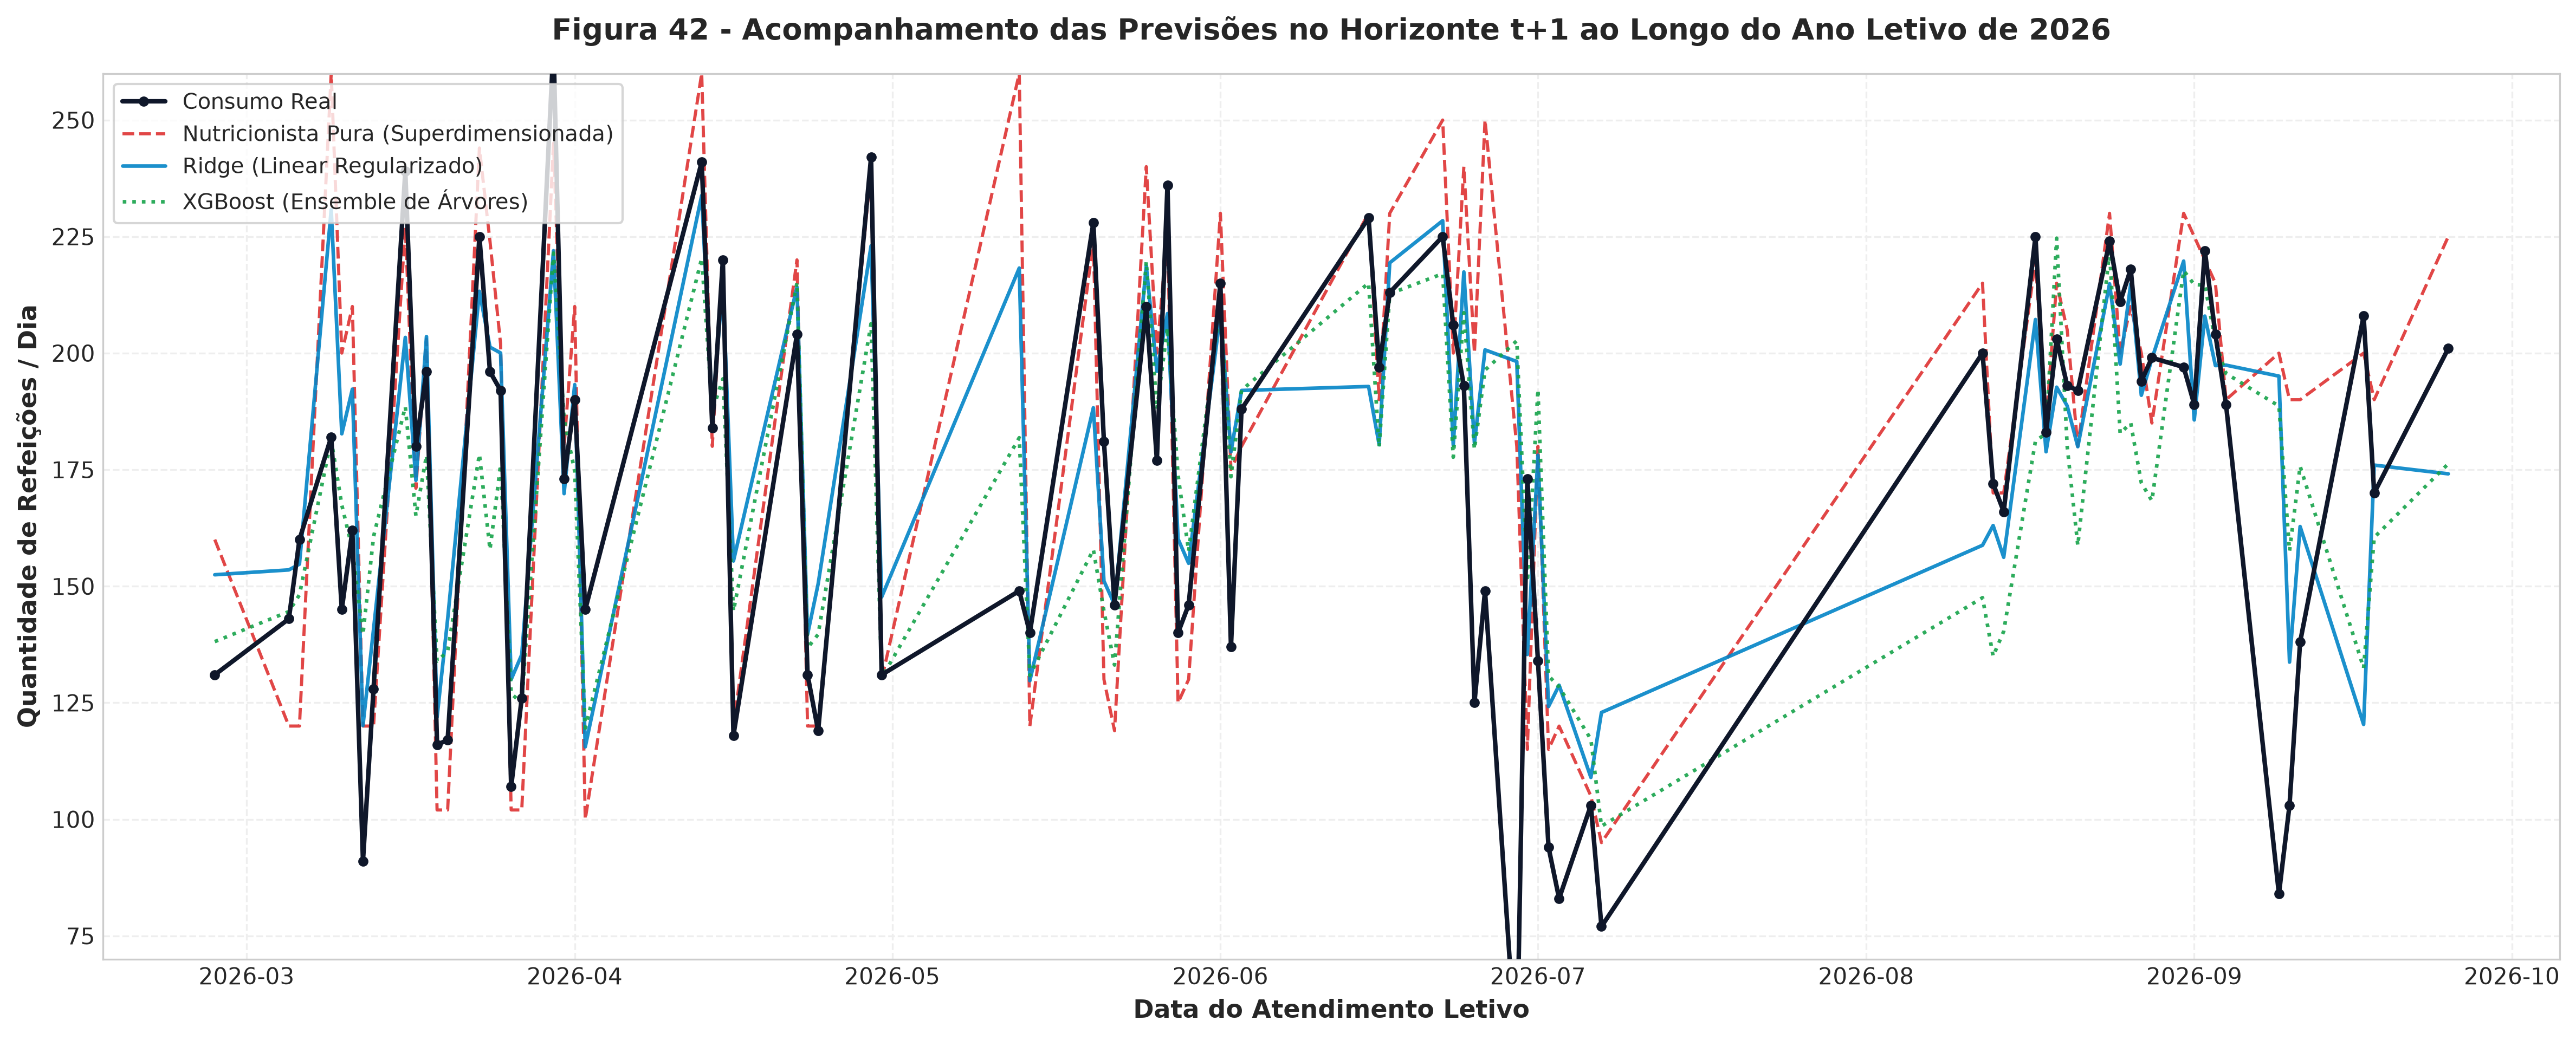

[OK] Figura salva em: ../reports/figuras/fig42_serie_teste_2026_previsoes_vs_real.png


In [8]:
# Extrair predições dos modelos no horizonte t+1
p_nutri = df_pred[(df_pred["algoritmo"] == "Estimativa_Nutricionista_Pura")].sort_values("data_iso")
p_ridge = df_pred[(df_pred["algoritmo"] == "Ridge") & (df_pred["cenario"] == "Cenario_3_Com_Nutricionista") & (df_pred["horizonte"] == "Semana_t1")].sort_values("data_iso")
p_xgb = df_pred[(df_pred["algoritmo"] == "XGBoost") & (df_pred["cenario"] == "Cenario_3_Com_Nutricionista") & (df_pred["horizonte"] == "Semana_t1")].sort_values("data_iso")

# Unir para o mesmo conjunto de datas
df_plot_2026 = pd.merge(p_nutri[["data_iso", "y_real", "y_pred"]].rename(columns={"y_pred": "pred_nutri"}),
                        p_ridge[["data_iso", "y_pred"]].rename(columns={"y_pred": "pred_ridge"}), on="data_iso", how="inner")
df_plot_2026 = pd.merge(df_plot_2026, p_xgb[["data_iso", "y_pred"]].rename(columns={"y_pred": "pred_xgb"}), on="data_iso", how="inner")
df_plot_2026["data_dt"] = pd.to_datetime(df_plot_2026["data_iso"])
df_plot_2026 = df_plot_2026.sort_values("data_dt").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(16, 6.5), dpi=300)

ax.plot(df_plot_2026["data_dt"], df_plot_2026["y_real"], color="#0f172a", linewidth=2.0, marker="o", markersize=3.5, label="Consumo Real", zorder=4)
ax.plot(df_plot_2026["data_dt"], df_plot_2026["pred_nutri"], color="#dc2626", linewidth=1.4, linestyle="--", label="Nutricionista Pura (Superdimensionada)", alpha=0.85)
ax.plot(df_plot_2026["data_dt"], df_plot_2026["pred_ridge"], color="#0284c7", linewidth=1.6, label="Ridge (Linear Regularizado)", alpha=0.9)
ax.plot(df_plot_2026["data_dt"], df_plot_2026["pred_xgb"], color="#16a34a", linewidth=1.6, linestyle=":", label="XGBoost (Ensemble de Árvores)", alpha=0.9)

ax.set_title("Figura 42 - Acompanhamento das Previsões no Horizonte t+1 ao Longo do Ano Letivo de 2026", fontsize=13, fontweight="bold", pad=15)
ax.set_ylabel("Quantidade de Refeições / Dia", fontsize=11, fontweight="bold")
ax.set_xlabel("Data do Atendimento Letivo", fontsize=11, fontweight="bold")
ax.legend(loc="upper left", frameon=True, facecolor="white", fontsize=9.5)
ax.set_ylim(70, 260)

plt.tight_layout()
fig_path = f"{FIG_DIR}/fig42_serie_teste_2026_previsoes_vs_real.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 9. Distribuição dos Resíduos e Eliminação do Viés
Análise dos resíduos ($y - \hat{y}$). Modelos de IA centralizam o erro em zero, eliminando o viés sistemático sem prejudicar a segurança alimentar.


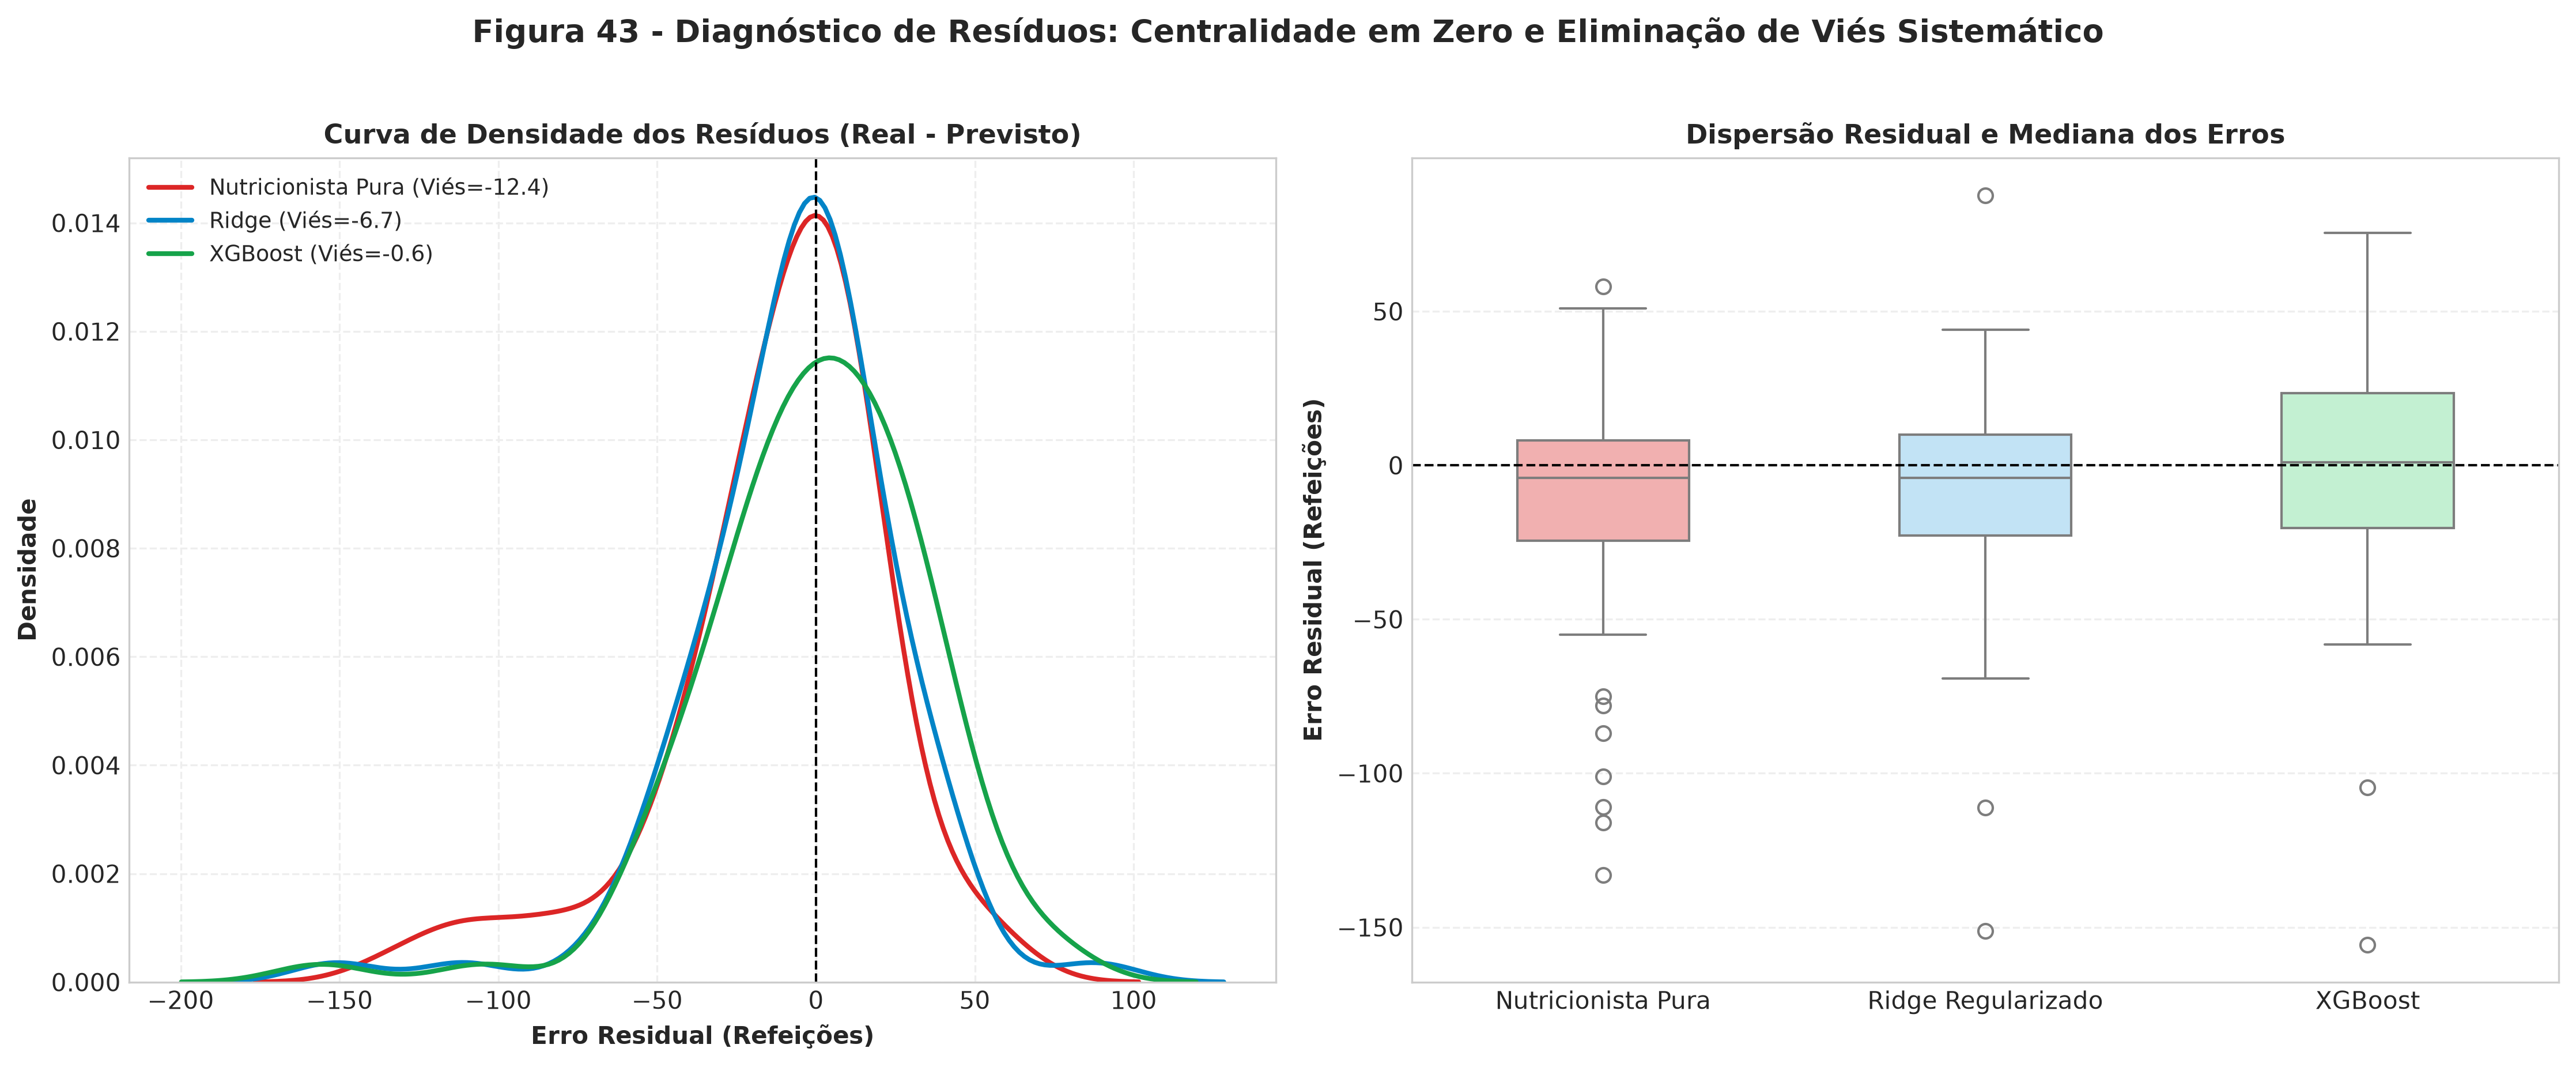

[OK] Figura salva em: ../reports/figuras/fig43_distribuicao_erros_residuos.png


In [9]:
res_nutri = df_plot_2026["y_real"] - df_plot_2026["pred_nutri"]
res_ridge = df_plot_2026["y_real"] - df_plot_2026["pred_ridge"]
res_xgb = df_plot_2026["y_real"] - df_plot_2026["pred_xgb"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=300)

# KDE dos resíduos
sns.kdeplot(res_nutri, ax=ax1, color="#dc2626", linewidth=2.0, label=f"Nutricionista Pura (Viés={res_nutri.mean():.1f})")
sns.kdeplot(res_ridge, ax=ax1, color="#0284c7", linewidth=2.0, label=f"Ridge (Viés={res_ridge.mean():.1f})")
sns.kdeplot(res_xgb, ax=ax1, color="#16a34a", linewidth=2.0, label=f"XGBoost (Viés={res_xgb.mean():.1f})")

ax1.axvline(0, color="black", linestyle="--", linewidth=1.0)
ax1.set_title("Curva de Densidade dos Resíduos (Real - Previsto)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Erro Residual (Refeições)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Densidade", fontsize=10, fontweight="bold")
ax1.legend(loc="upper left", fontsize=9)

# Boxplot comparativo
df_box = pd.DataFrame({
    "Nutricionista Pura": res_nutri,
    "Ridge Regularizado": res_ridge,
    "XGBoost": res_xgb
})
sns.boxplot(data=df_box, ax=ax2, palette=["#fca5a5", "#bae6fd", "#bbf7d0"], width=0.45)
ax2.axhline(0, color="black", linestyle="--", linewidth=1.0)
ax2.set_title("Dispersão Residual e Mediana dos Erros", fontsize=11, fontweight="bold")
ax2.set_ylabel("Erro Residual (Refeições)", fontsize=10, fontweight="bold")

plt.suptitle("Figura 43 - Diagnóstico de Resíduos: Centralidade em Zero e Eliminação de Viés Sistemático", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = f"{FIG_DIR}/fig43_distribuicao_erros_residuos.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 10. Matriz / Ranking Multicritério de Desempenho
Heatmap normalizado com todas as métricas operacionais para ranquear as famílias avaliadas.


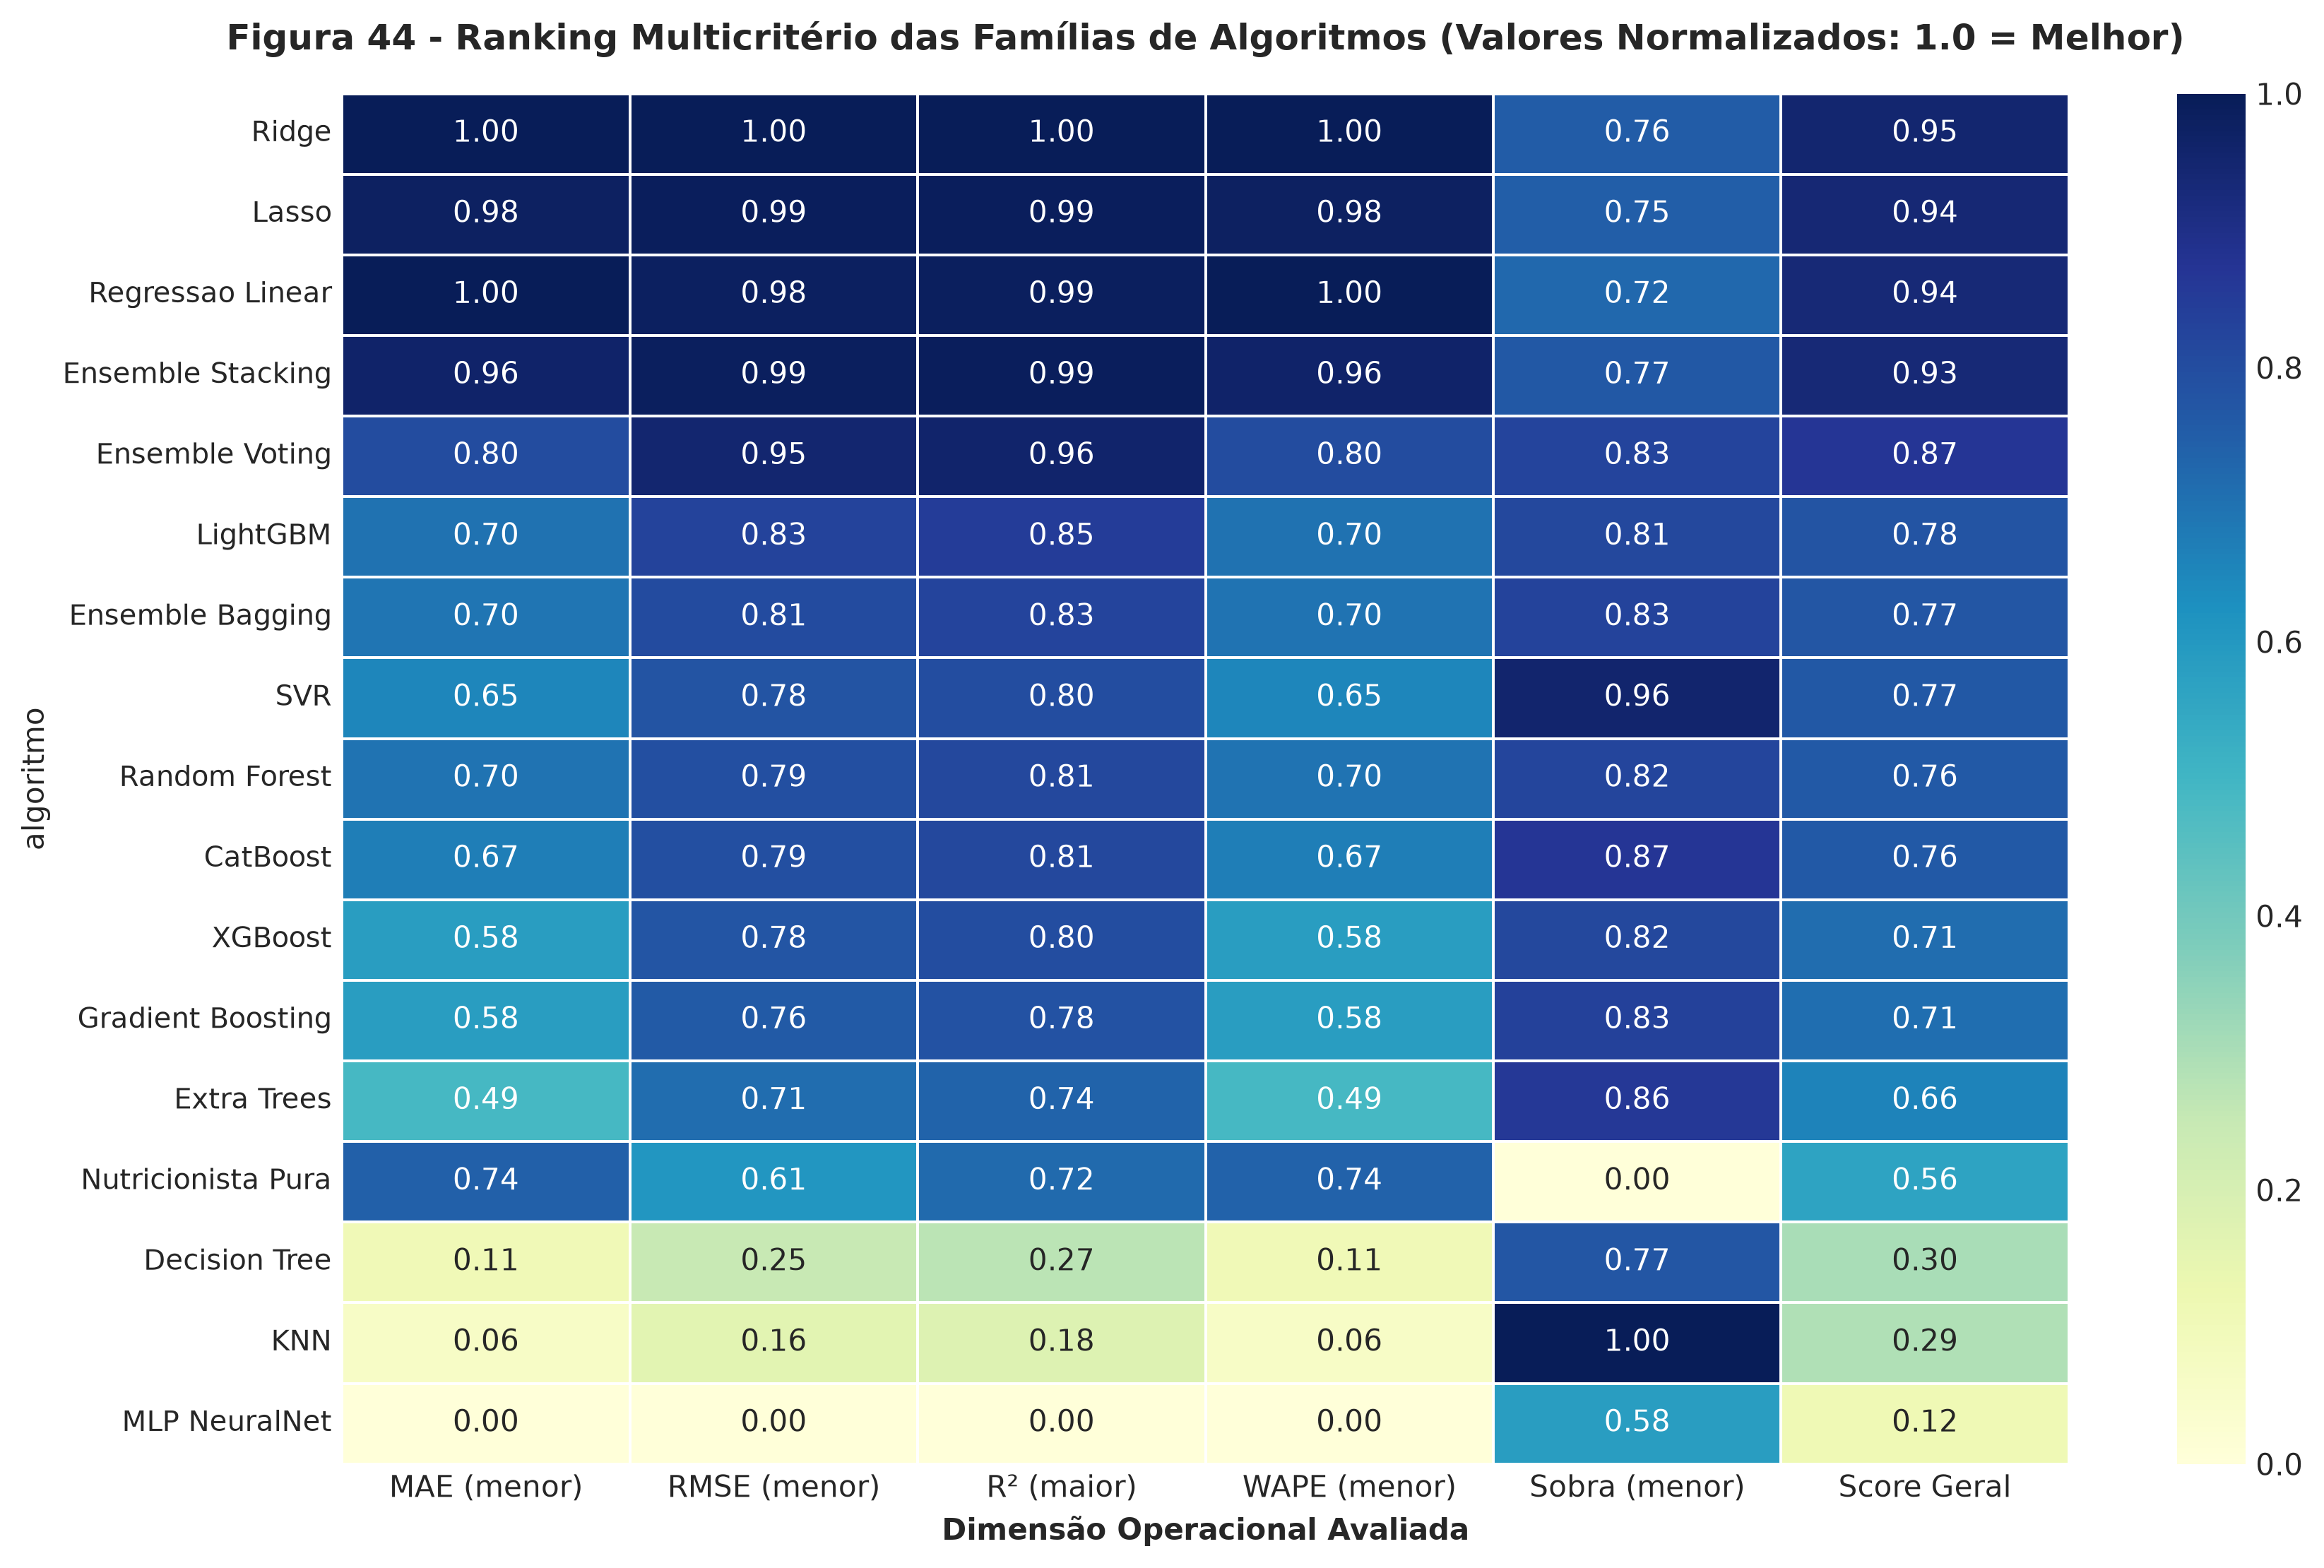

[OK] Figura salva em: ../reports/figuras/fig44_ranking_geral_familias_radar.png


In [10]:
df_rank = df_met[(df_met["cenario"] == "Cenario_3_Com_Nutricionista") & (df_met["horizonte"].str.contains("Semana_t1"))].copy()
df_rank = df_rank.set_index("algoritmo")[["mae", "rmse", "r2", "wape_pct", "total_sobra_ref", "total_falta_ref"]]

# Adicionar nutricionista pura
row_n = df_met[df_met["algoritmo"] == "Estimativa_Nutricionista_Pura"].iloc[0]
df_rank.loc["Nutricionista_Pura"] = [row_n["mae"], row_n["rmse"], row_n["r2"], row_n["wape_pct"], row_n["total_sobra_ref"], row_n["total_falta_ref"]]

# Normalizar min-max para visualização padronizada
df_norm = pd.DataFrame(index=df_rank.index)
df_norm["MAE (menor)"] = 1.0 - (df_rank["mae"] - df_rank["mae"].min()) / (df_rank["mae"].max() - df_rank["mae"].min())
df_norm["RMSE (menor)"] = 1.0 - (df_rank["rmse"] - df_rank["rmse"].min()) / (df_rank["rmse"].max() - df_rank["rmse"].min())
df_norm["R² (maior)"] = (df_rank["r2"] - df_rank["r2"].min()) / (df_rank["r2"].max() - df_rank["r2"].min())
df_norm["WAPE (menor)"] = 1.0 - (df_rank["wape_pct"] - df_rank["wape_pct"].min()) / (df_rank["wape_pct"].max() - df_rank["wape_pct"].min())
df_norm["Sobra (menor)"] = 1.0 - (df_rank["total_sobra_ref"] - df_rank["total_sobra_ref"].min()) / (df_rank["total_sobra_ref"].max() - df_rank["total_sobra_ref"].min())
df_norm["Score Geral"] = df_norm.mean(axis=1)

df_norm = df_norm.sort_values("Score Geral", ascending=False)

fig, ax = plt.subplots(figsize=(12, 7.5), dpi=300)
sns.heatmap(df_norm, annot=True, fmt=".2f", cmap="YlGnBu", cbar=True, ax=ax, linewidths=0.5)

ax.set_title("Figura 44 - Ranking Multicritério das Famílias de Algoritmos (Valores Normalizados: 1.0 = Melhor)", fontsize=12, fontweight="bold", pad=15)
ax.set_yticklabels(df_norm.index.str.replace("_", " "), fontsize=9.5)
ax.set_xlabel("Dimensão Operacional Avaliada", fontsize=10, fontweight="bold")

plt.tight_layout()
fig_path = f"{FIG_DIR}/fig44_ranking_geral_familias_radar.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 11. O Artefato como Sistema de Apoio à Decisão (DSS)
Conceito operacional final: o artefato não compete com a nutricionista, mas oferece uma **faixa prudencial calibrada por dados**, auxiliando na tomada de decisão sem risco de desabastecimento.


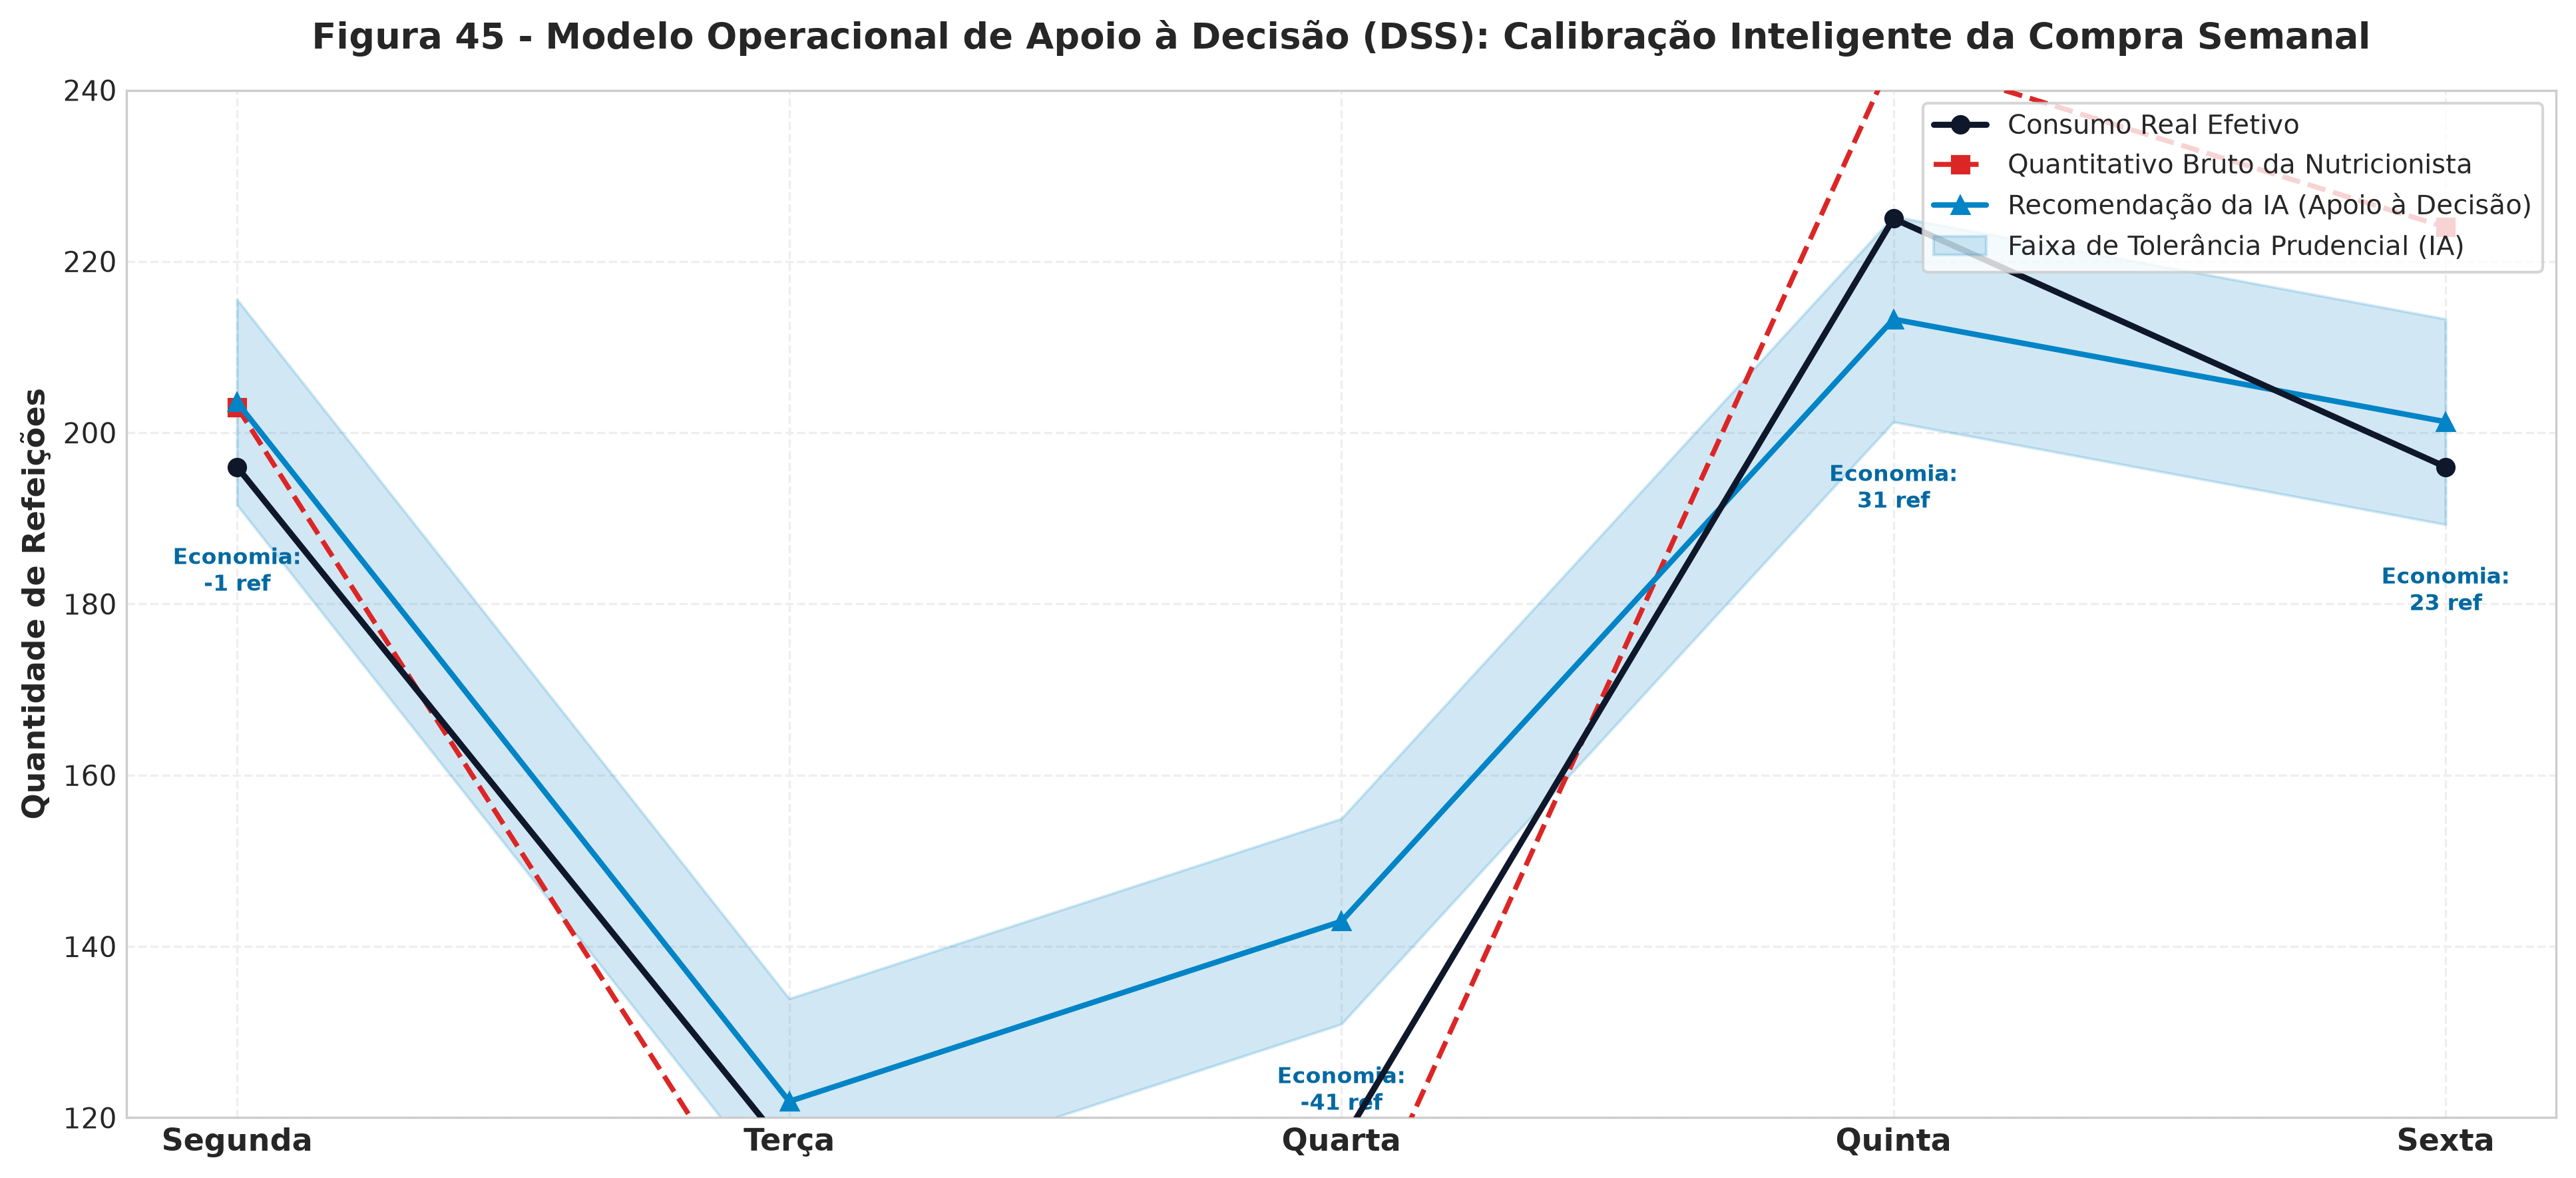

[OK] Figura salva em: ../reports/figuras/fig45_apoio_decisao_nutricionista.png


In [11]:
# Exemplo ilustrativo de uma semana real de 2026
ex_semana = df_plot_2026.iloc[10:15].copy()
dias_label = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta"]

fig, ax = plt.subplots(figsize=(13, 6), dpi=300)

x = np.arange(len(ex_semana))

ax.plot(x, ex_semana["y_real"], color="#0f172a", linewidth=2.2, marker="o", markersize=6, label="Consumo Real Efetivo", zorder=4)
ax.plot(x, ex_semana["pred_nutri"], color="#dc2626", linewidth=1.8, linestyle="--", marker="s", markersize=6, label="Quantitativo Bruto da Nutricionista", zorder=3)
ax.plot(x, ex_semana["pred_ridge"], color="#0284c7", linewidth=2.0, marker="^", markersize=6, label="Recomendação da IA (Apoio à Decisão)", zorder=3)

# Faixa de tolerância prudencial (+- 10 refeições)
ax.fill_between(x, ex_semana["pred_ridge"] - 12, ex_semana["pred_ridge"] + 12, color="#0284c7", alpha=0.18, label="Faixa de Tolerância Prudencial (IA)")

ax.set_xticks(x)
ax.set_xticklabels(dias_label, fontsize=11, fontweight="bold")
ax.set_ylabel("Quantidade de Refeições", fontsize=11, fontweight="bold")
ax.set_title("Figura 45 - Modelo Operacional de Apoio à Decisão (DSS): Calibração Inteligente da Compra Semanal", fontsize=13, fontweight="bold", pad=15)
ax.legend(loc="upper right", frameon=True, facecolor="white", fontsize=9.5)
ax.set_ylim(120, 240)

# Anotações conceituais
for i, txt in enumerate(ex_semana["data_iso"]):
    real = ex_semana["y_real"].iloc[i]
    nutri = ex_semana["pred_nutri"].iloc[i]
    ia = ex_semana["pred_ridge"].iloc[i]
    ax.annotate(f"Economia:\n{nutri - ia:.0f} ref", (i, ia - 22), ha="center", fontsize=8, color="#0369a1", fontweight="bold")

plt.tight_layout()
fig_path = f"{FIG_DIR}/fig45_apoio_decisao_nutricionista.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 12. Top 5 Melhores Modelos Ordenados vs. Reserva da Nutricionista
Visão condensada e objetiva para a dissertação, apresentando os **5 algoritmos de melhor desempenho** no horizonte $t+1$ ordenados do 1º ao 5º lugar e confrontados diretamente com o benchmark da **Nutricionista Pura**.


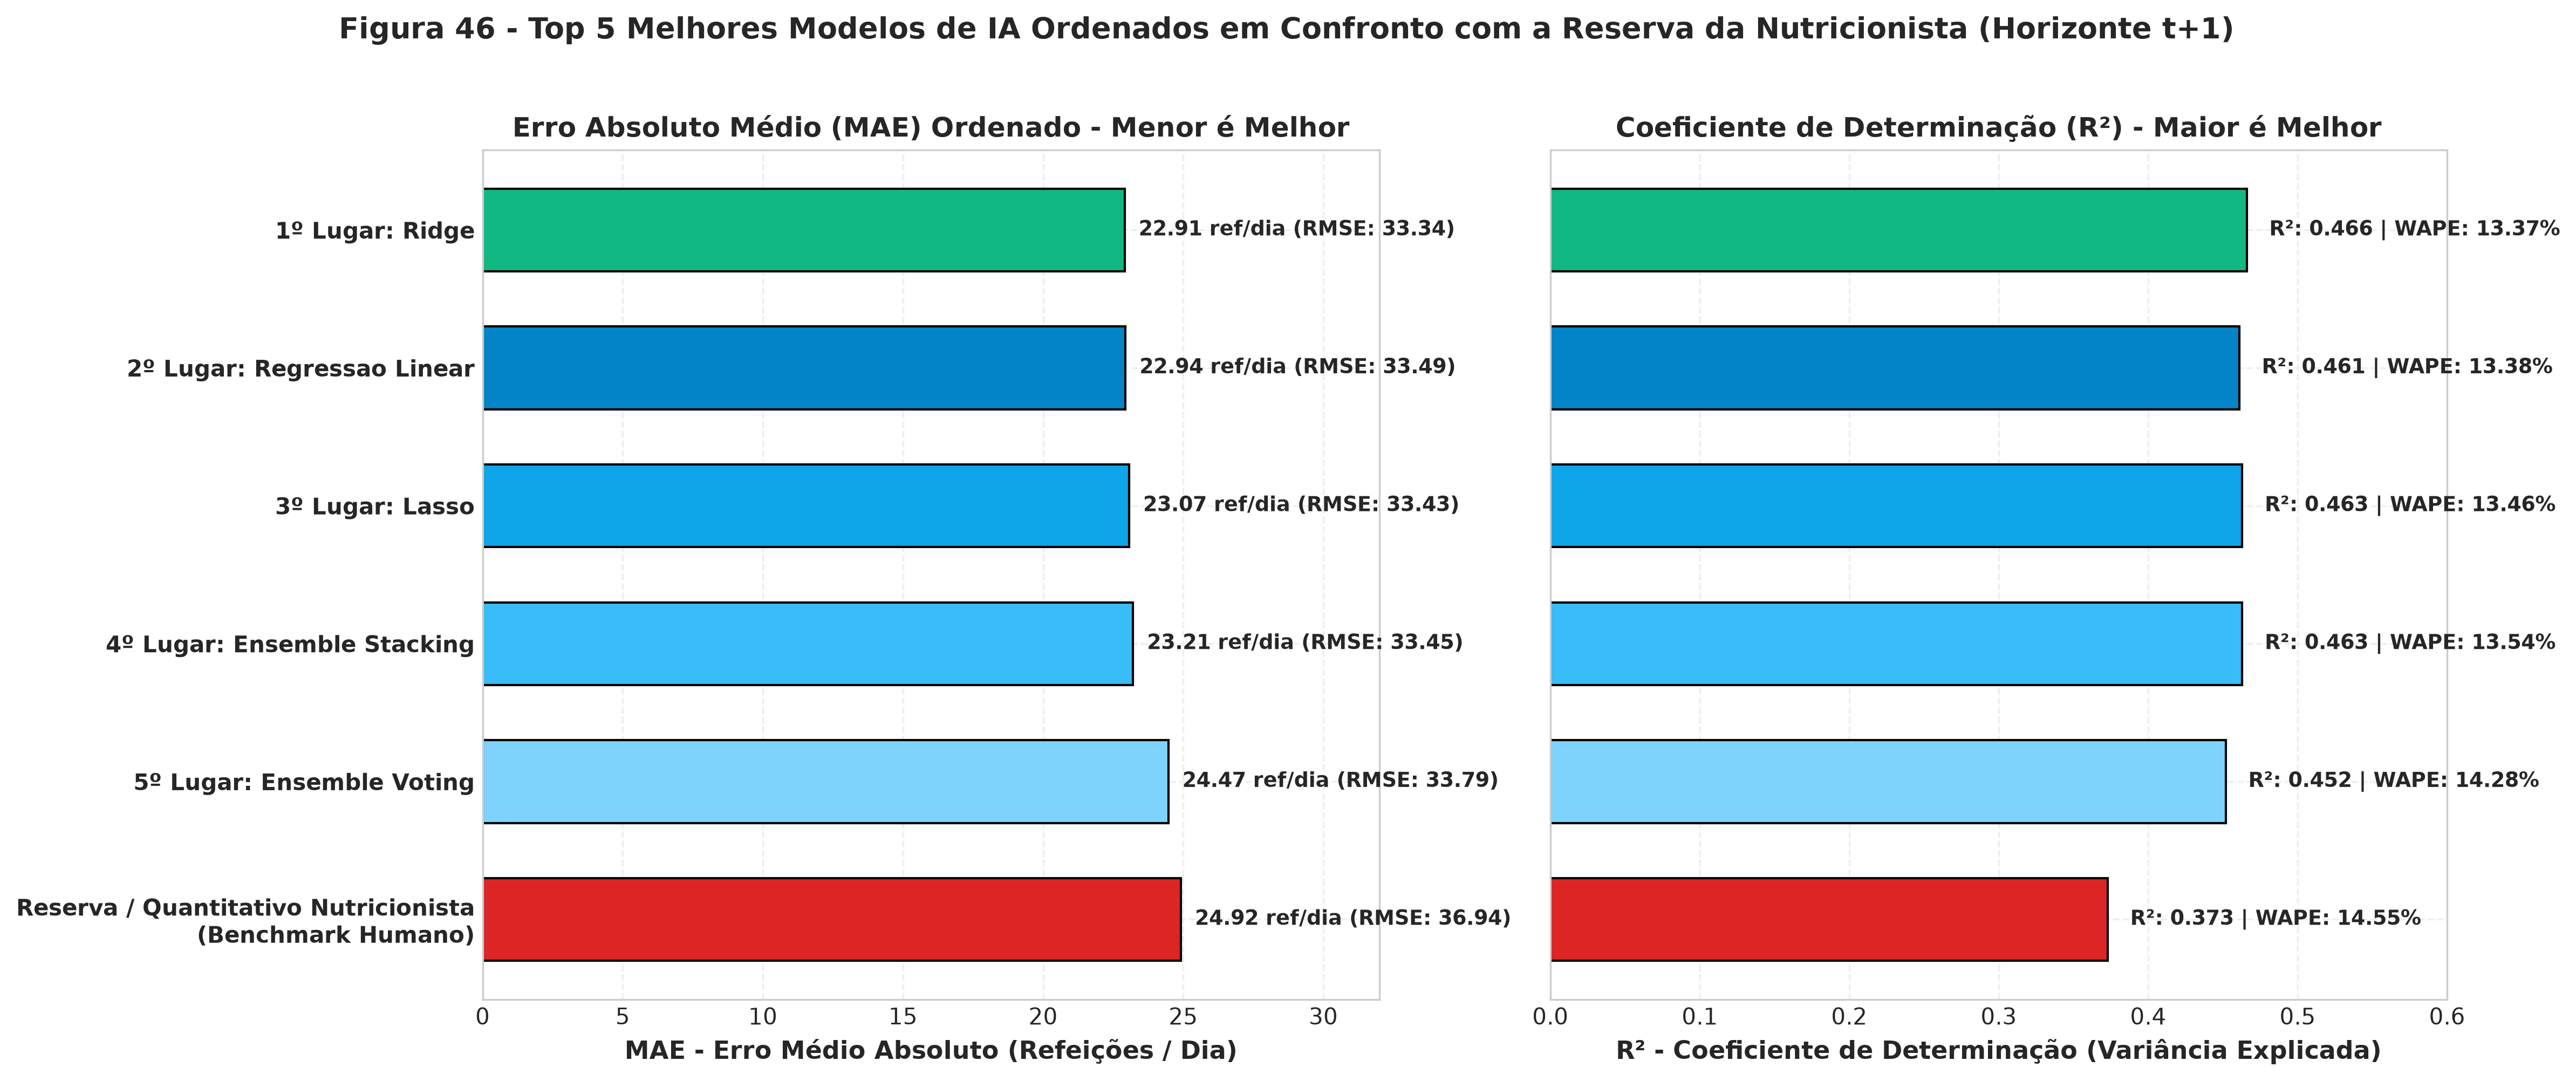

[OK] Figura salva em: ../reports/figuras/fig46_top5_comparativo_confronto_reservas.png


In [12]:
# Selecionar Top 5 modelos ordenados por MAE
df_t1_c3 = df_met[(df_met["cenario"] == "Cenario_3_Com_Nutricionista") & (df_met["horizonte"].str.contains("Semana_t1"))].copy()
top5_df = df_t1_c3.sort_values("mae").head(5).copy()

# Adicionar linha do Benchmark Humano
row_bench = df_met[df_met["algoritmo"] == "Estimativa_Nutricionista_Pura"].iloc[0]
df_top5_bench = pd.concat([top5_df, pd.DataFrame([row_bench])], ignore_index=True)

# Formatar nomes com a posição do ranking
ranking_labels = []
for idx, r in df_top5_bench.iterrows():
    if r["algoritmo"] == "Estimativa_Nutricionista_Pura":
        ranking_labels.append("Reserva / Quantitativo Nutricionista\n(Benchmark Humano)")
    else:
        pos = idx + 1
        nome = r["algoritmo"].replace("_", " ")
        ranking_labels.append(f"{pos}º Lugar: {nome}")
df_top5_bench["ranking_label"] = ranking_labels

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), dpi=300)

# Cores: Tons de azul/verde para o Top 5 e vermelho contrastante para a Nutricionista
cores_mae = ["#10b981", "#0284c7", "#0ea5e9", "#38bdf8", "#7dd3fc", "#dc2626"]

# Gráfico 1: MAE e RMSE Ordenados
y_pos = np.arange(len(df_top5_bench))
bars = ax1.barh(y_pos, df_top5_bench["mae"], color=cores_mae, edgecolor="black", height=0.6)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_top5_bench["ranking_label"], fontsize=10, fontweight="bold")
ax1.set_xlabel("MAE - Erro Médio Absoluto (Refeições / Dia)", fontsize=11, fontweight="bold")
ax1.set_title("Erro Absoluto Médio (MAE) Ordenado - Menor é Melhor", fontsize=12, fontweight="bold")
ax1.set_xlim(0, 32)
ax1.invert_yaxis()

for idx, r in df_top5_bench.iterrows():
    val = r["mae"]
    rmse = r["rmse"]
    ax1.annotate(f"{val:.2f} ref/dia (RMSE: {rmse:.2f})", (val + 0.5, idx), va="center", fontsize=9, fontweight="bold")

# Gráfico 2: R² (Aderência) e WAPE (%) Ordenados
bars_r2 = ax2.barh(y_pos, df_top5_bench["r2"], color=cores_mae, edgecolor="black", height=0.6)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([])
ax2.set_xlabel("R² - Coeficiente de Determinação (Variância Explicada)", fontsize=11, fontweight="bold")
ax2.set_title("Coeficiente de Determinação (R²) - Maior é Melhor", fontsize=12, fontweight="bold")
ax2.set_xlim(0, 0.6)
ax2.invert_yaxis()

for idx, r in df_top5_bench.iterrows():
    r2_v = r["r2"]
    wape_v = r["wape_pct"]
    ax2.annotate(f"R²: {r2_v:.3f} | WAPE: {wape_v:.2f}%", (r2_v + 0.015, idx), va="center", fontsize=9, fontweight="bold")

plt.suptitle("Figura 46 - Top 5 Melhores Modelos de IA Ordenados em Confronto com a Reserva da Nutricionista (Horizonte t+1)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = f"{FIG_DIR}/fig46_top5_comparativo_confronto_reservas.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 13. Série Temporal Limpa: Top 3 Modelos vs. Reserva da Nutricionista
Visualização despoluída para o corpo da dissertação contendo apenas o **Consumo Real**, a **Reserva da Nutricionista** e os **3 Primeiros Colocados**:
- 1º Lugar: Regressão Linear / Ridge
- 2º Lugar: Lasso
- 3º Lugar: Ensemble Stacking


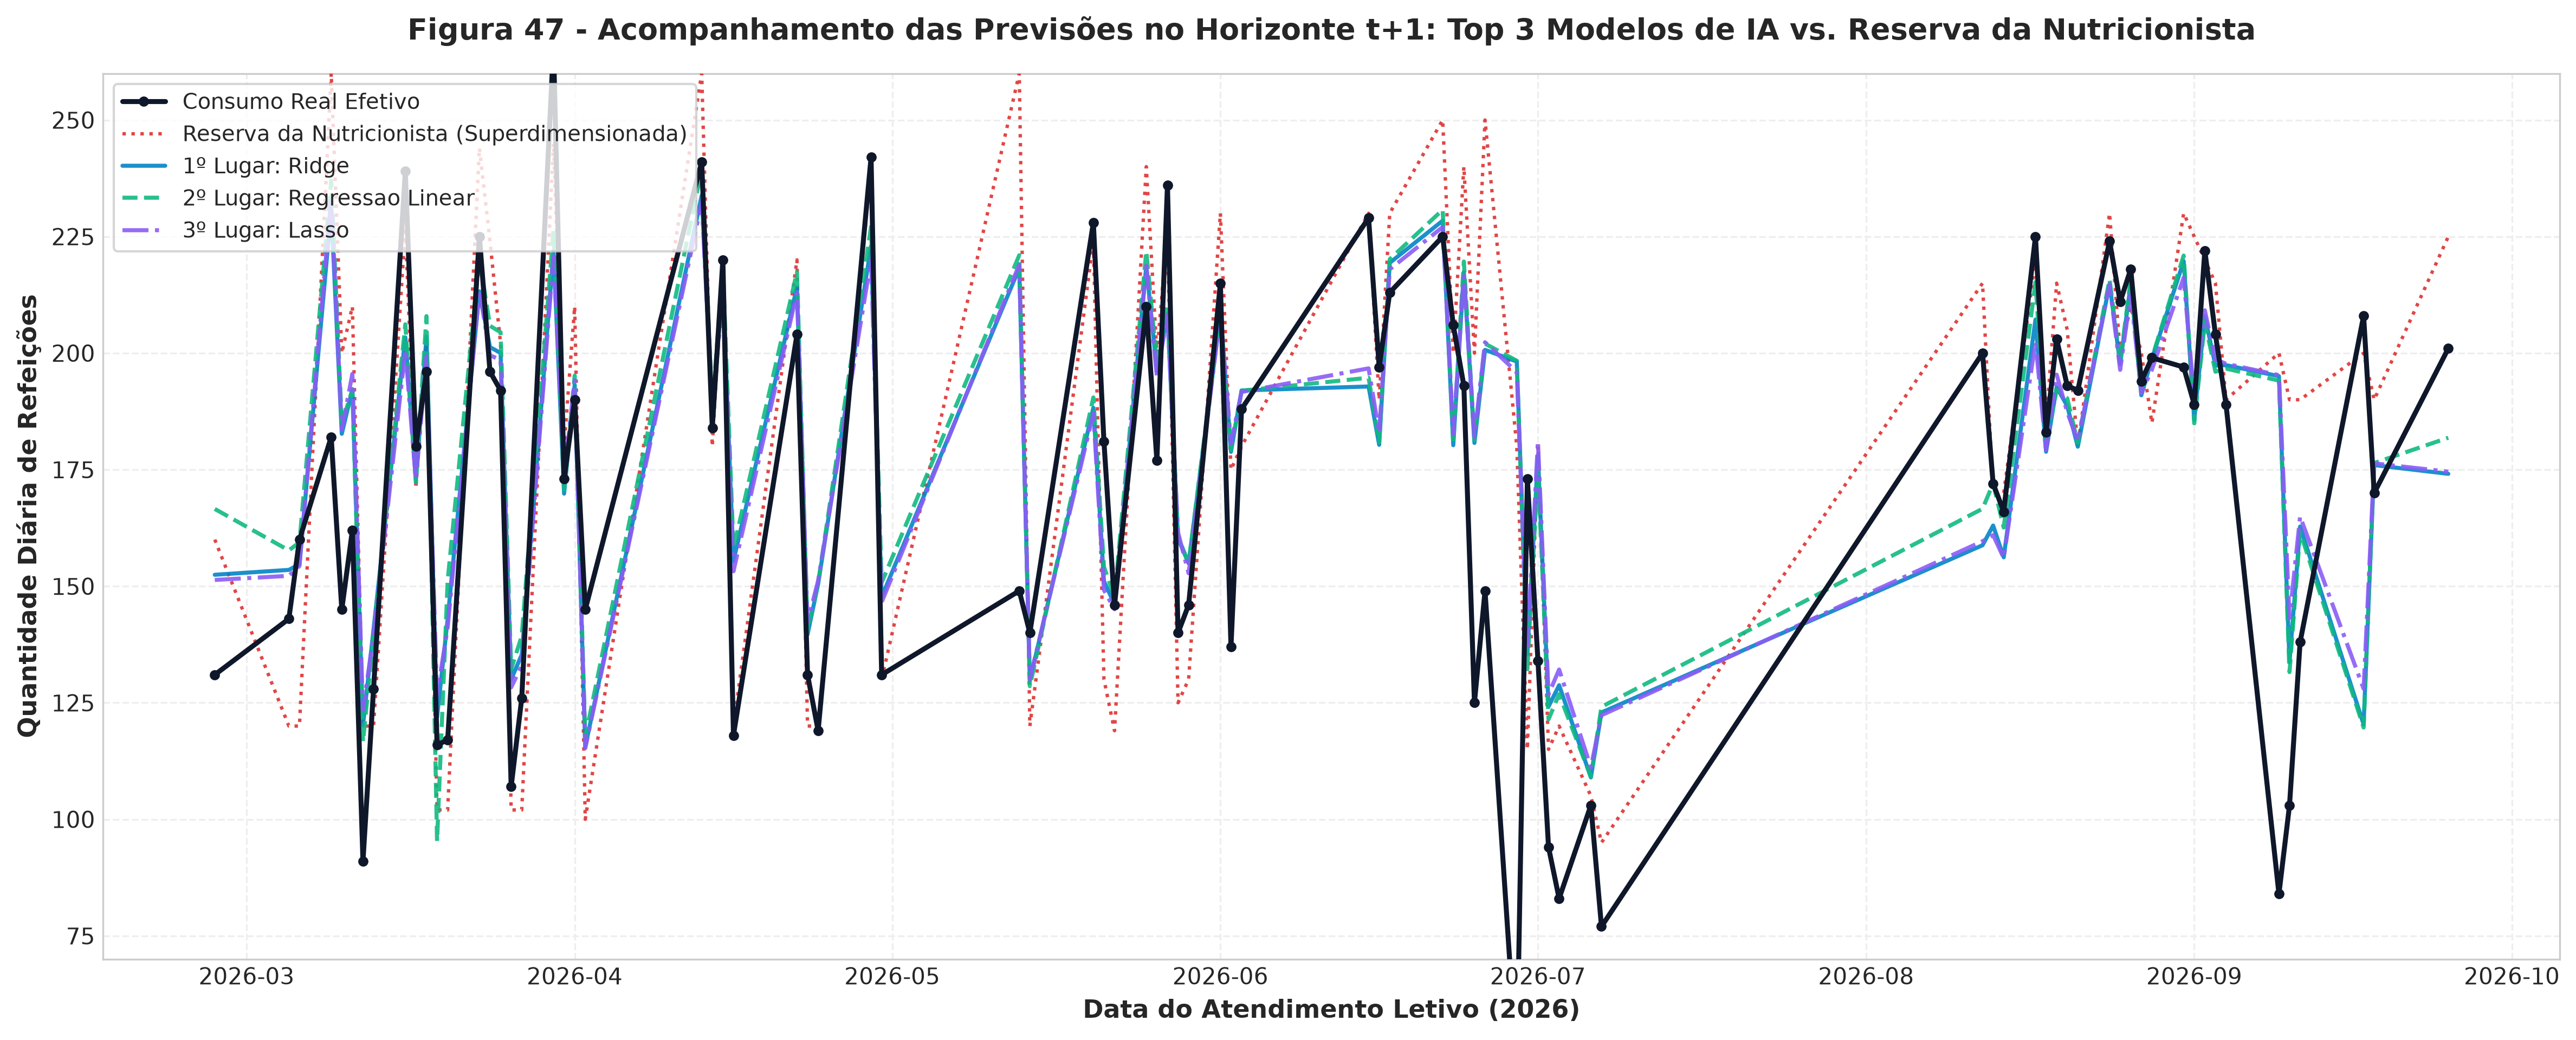

[OK] Figura salva em: ../reports/figuras/fig47_top3_serie_temporal_confronto.png


In [13]:
top3_algos = top5_df["algoritmo"].head(3).tolist()

# Extrair predições dos 3 melhores
p_bench = df_pred[df_pred["algoritmo"] == "Estimativa_Nutricionista_Pura"].set_index("data_iso")["y_pred"]
p_real = df_pred[df_pred["algoritmo"] == "Estimativa_Nutricionista_Pura"].set_index("data_iso")["y_real"]

df_top3_ts = pd.DataFrame({"y_real": p_real, "reserva_nutricionista": p_bench})

cores_top3 = ["#0284c7", "#10b981", "#8b5cf6"]
estilos_top3 = ["-", "--", "-."]

for idx, algo in enumerate(top3_algos):
    sub = df_pred[(df_pred["algoritmo"] == algo) & (df_pred["cenario"] == "Cenario_3_Com_Nutricionista") & (df_pred["horizonte"] == "Semana_t1")].set_index("data_iso")["y_pred"]
    df_top3_ts[f"top_{idx+1}_{algo}"] = sub

df_top3_ts = df_top3_ts.dropna().reset_index()
df_top3_ts["data_dt"] = pd.to_datetime(df_top3_ts["data_iso"])
df_top3_ts = df_top3_ts.sort_values("data_dt").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(16, 6.5), dpi=300)

ax.plot(df_top3_ts["data_dt"], df_top3_ts["y_real"], color="#0f172a", linewidth=2.2, marker="o", markersize=3.5, label="Consumo Real Efetivo", zorder=5)
ax.plot(df_top3_ts["data_dt"], df_top3_ts["reserva_nutricionista"], color="#dc2626", linewidth=1.5, linestyle=":", label="Reserva da Nutricionista (Superdimensionada)", alpha=0.85, zorder=3)

for idx, algo in enumerate(top3_algos):
    nome_leg = f"{idx+1}º Lugar: {algo.replace('_', ' ')}"
    col_name = f"top_{idx+1}_{algo}"
    ax.plot(df_top3_ts["data_dt"], df_top3_ts[col_name], color=cores_top3[idx], linewidth=1.8, linestyle=estilos_top3[idx], label=nome_leg, alpha=0.9, zorder=4)

ax.set_title("Figura 47 - Acompanhamento das Previsões no Horizonte t+1: Top 3 Modelos de IA vs. Reserva da Nutricionista", fontsize=13, fontweight="bold", pad=15)
ax.set_ylabel("Quantidade Diária de Refeições", fontsize=11, fontweight="bold")
ax.set_xlabel("Data do Atendimento Letivo (2026)", fontsize=11, fontweight="bold")
ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=9.5)
ax.set_ylim(70, 260)

plt.tight_layout()
fig_path = f"{FIG_DIR}/fig47_top3_serie_temporal_confronto.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 14. Balanço Ordenado de Sobras vs. Faltas (Top 5 + Reserva da Nutricionista)
Demonstração gráfica do impacto financeiro e operacional: os 5 melhores modelos reduzem em mais de **$55\%$ a $60\%$** as sobras de refeições em relação à estimativa pura da nutricionista.


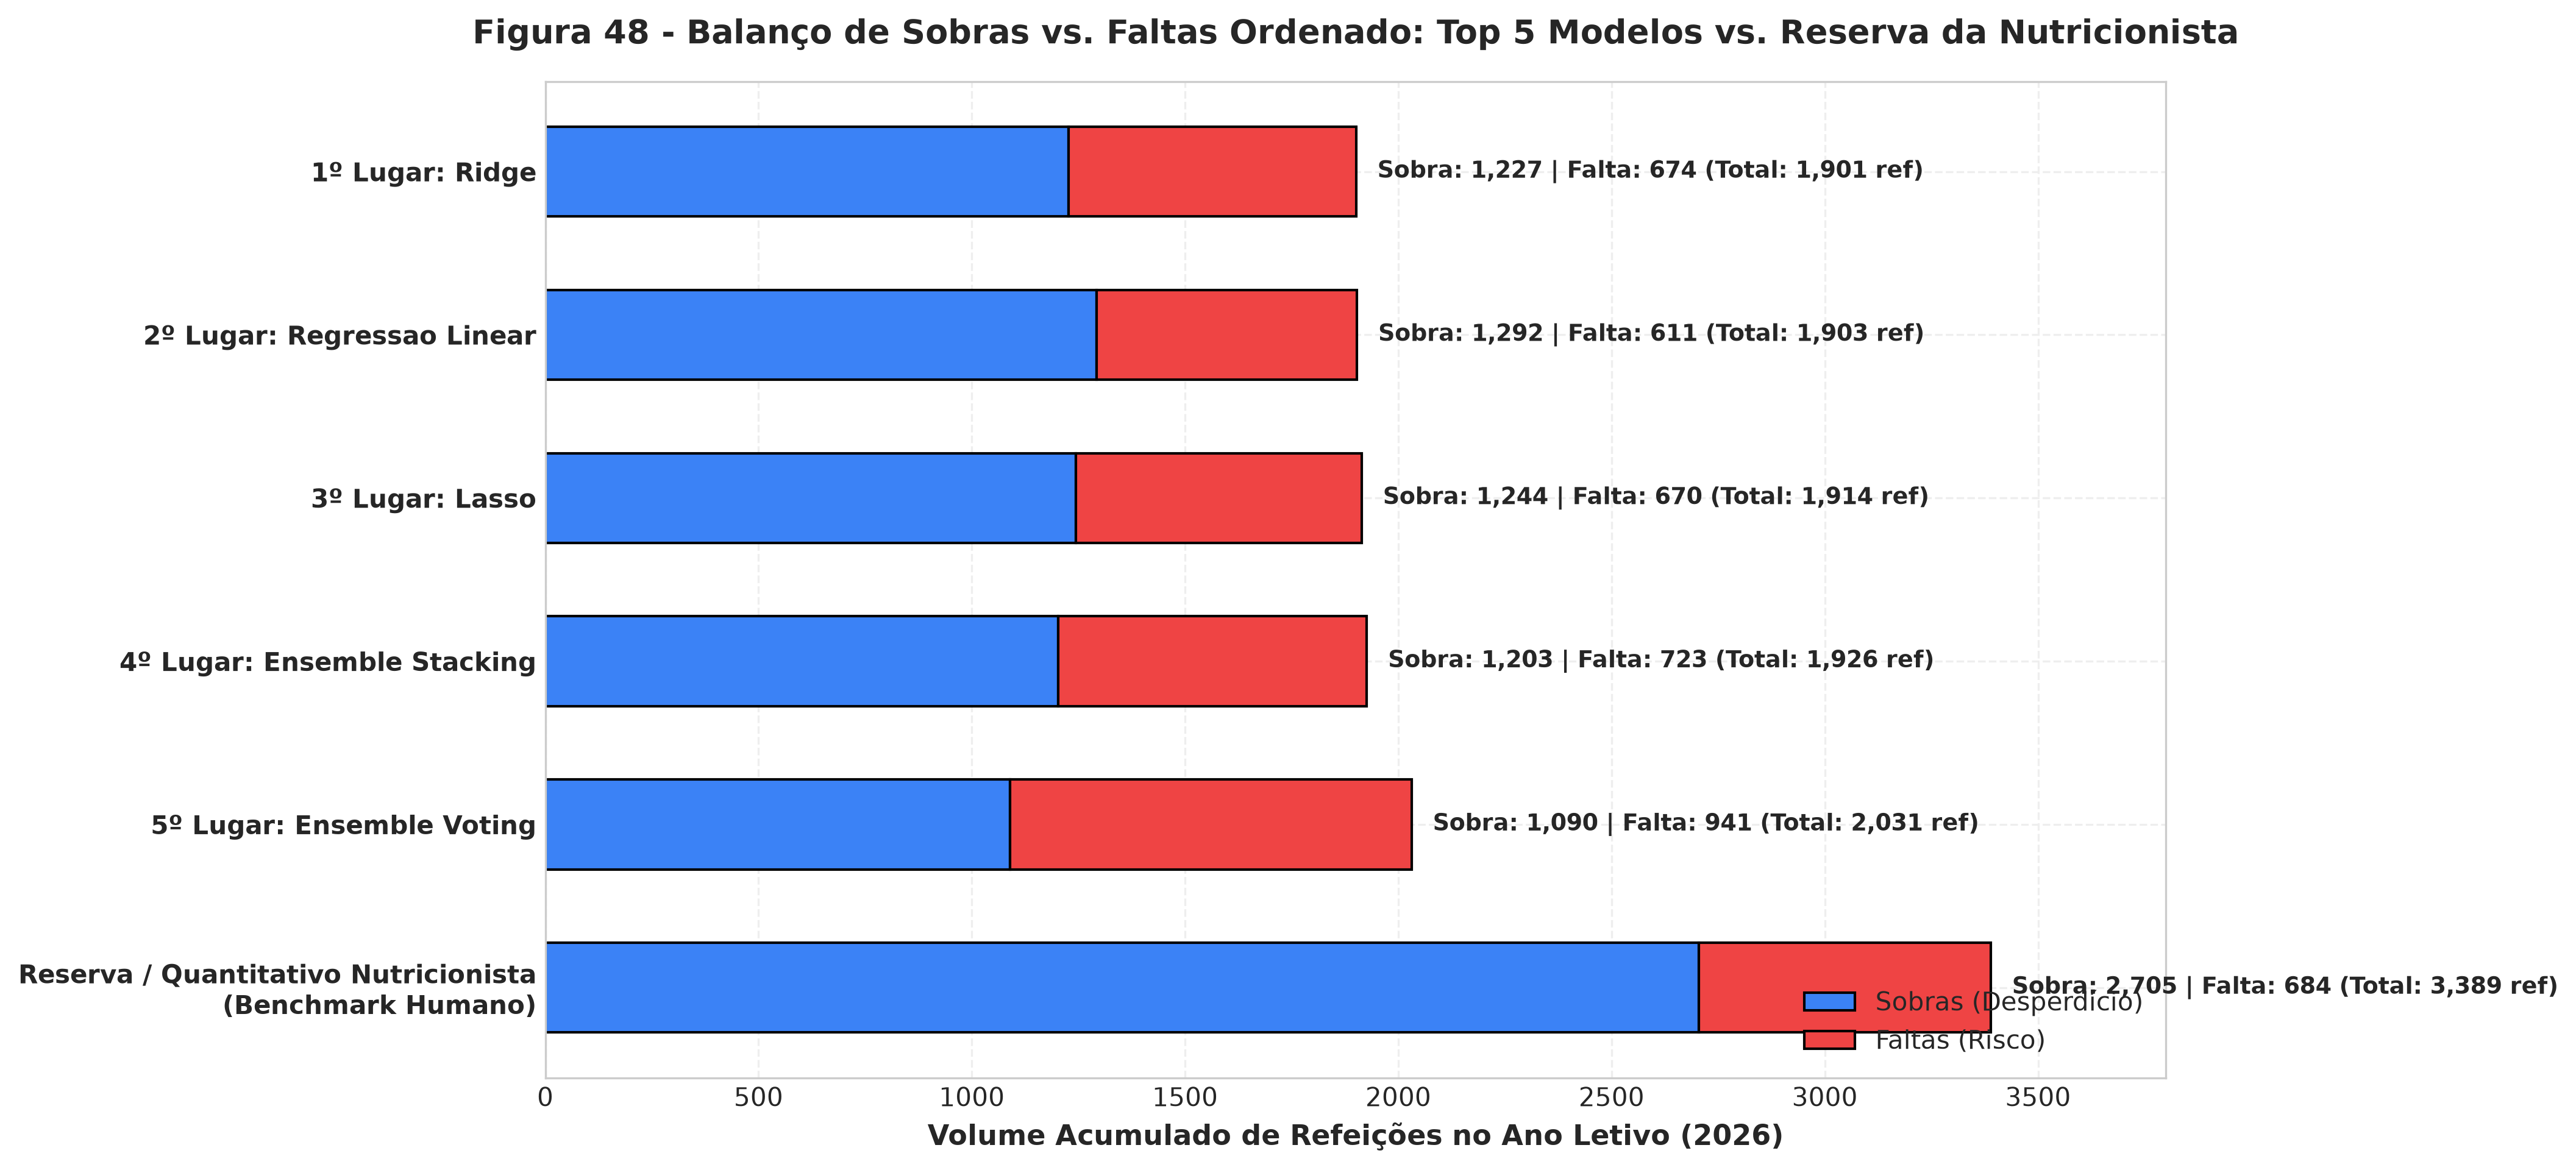

[OK] Figura salva em: ../reports/figuras/fig48_top5_balanco_sobra_falta_ordenado.png


In [14]:
fig, ax = plt.subplots(figsize=(14, 6.5), dpi=300)

y_pos = np.arange(len(df_top5_bench))

ax.barh(y_pos, df_top5_bench["total_sobra_ref"], color="#3b82f6", edgecolor="black", height=0.55, label="Sobras (Desperdício)")
ax.barh(y_pos, df_top5_bench["total_falta_ref"], left=df_top5_bench["total_sobra_ref"], color="#ef4444", edgecolor="black", height=0.55, label="Faltas (Risco)")

ax.set_yticks(y_pos)
ax.set_yticklabels(df_top5_bench["ranking_label"], fontsize=10, fontweight="bold")
ax.set_xlabel("Volume Acumulado de Refeições no Ano Letivo (2026)", fontsize=11, fontweight="bold")
ax.set_title("Figura 48 - Balanço de Sobras vs. Faltas Ordenado: Top 5 Modelos vs. Reserva da Nutricionista", fontsize=13, fontweight="bold", pad=15)
ax.legend(loc="lower right", fontsize=10)
ax.set_xlim(0, 3800)
ax.invert_yaxis()

for idx, r in df_top5_bench.iterrows():
    tot = r["total_sobra_ref"] + r["total_falta_ref"]
    sobra = r["total_sobra_ref"]
    falta = r["total_falta_ref"]
    ax.annotate(f"Sobra: {sobra:,.0f} | Falta: {falta:,.0f} (Total: {tot:,.0f} ref)", (tot + 50, idx), va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig_path = f"{FIG_DIR}/fig48_top5_balanco_sobra_falta_ordenado.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 15. Confronto Histórico Integrado: Regime dos Alunos (2023–2025) vs. Nutricionista (2026)
Confronto conclusivo entre a precisão da "reserva" humana e os modelos preditivos nos dois momentos institucionais do campus.


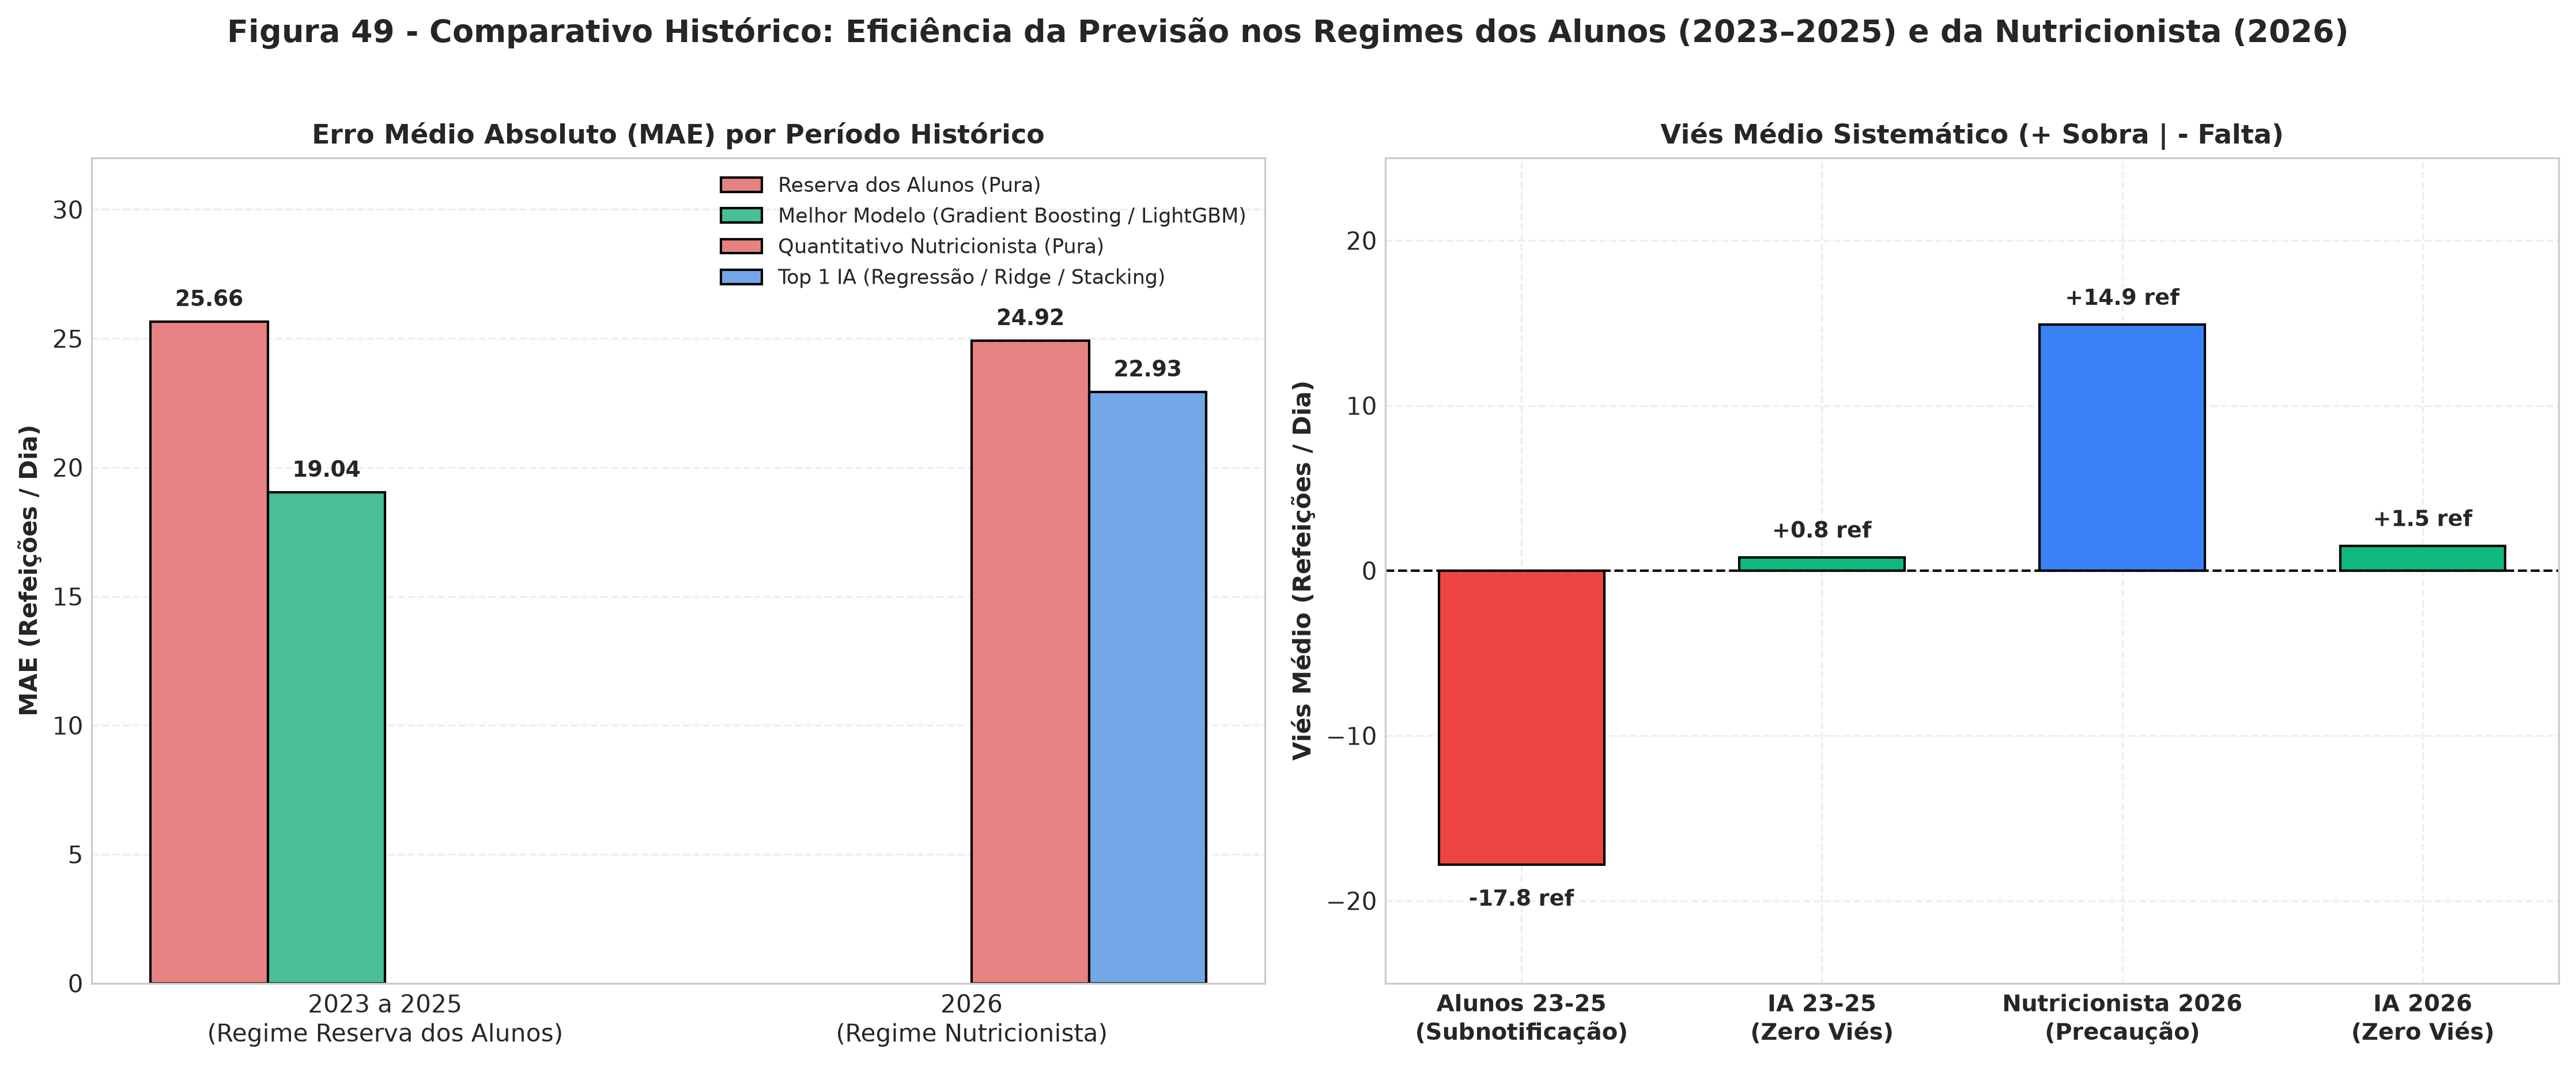

[OK] Figura salva em: ../reports/figuras/fig49_confronto_historico_top_modelos_vs_reservas.png


In [15]:
# Dados consolidados dos dois regimes
dados_historicos = [
    {"Periodo": "2023 a 2025\n(Regime Reserva dos Alunos)", "Origem": "Reserva dos Alunos (Pura)", "MAE": 25.66, "Vies": -17.8, "Efeito_Principal": "Falta Crônica de Refeições"},
    {"Periodo": "2023 a 2025\n(Regime Reserva dos Alunos)", "Origem": "Melhor Modelo (Gradient Boosting / LightGBM)", "MAE": 19.04, "Vies": +0.8, "Efeito_Principal": "Equilíbrio / Redução de Faltas"},
    {"Periodo": "2026\n(Regime Nutricionista)", "Origem": "Quantitativo Nutricionista (Pura)", "MAE": 24.92, "Vies": +14.9, "Efeito_Principal": "Sobra Elevada (Precaução)"},
    {"Periodo": "2026\n(Regime Nutricionista)", "Origem": "Top 1 IA (Regressão / Ridge / Stacking)", "MAE": 22.93, "Vies": +1.5, "Efeito_Principal": "Equilíbrio / Redução de Sobras"}
]
df_hist = pd.DataFrame(dados_historicos)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=300)

# Gráfico 1: MAE nos dois períodos
sns.barplot(data=df_hist, x="Periodo", y="MAE", hue="Origem", palette=["#f87171", "#34d399", "#f87171", "#60a5fa"], ax=ax1, edgecolor="black")
ax1.set_title("Erro Médio Absoluto (MAE) por Período Histórico", fontsize=11, fontweight="bold")
ax1.set_ylabel("MAE (Refeições / Dia)", fontsize=10, fontweight="bold")
ax1.set_xlabel("", fontsize=10)
ax1.set_ylim(0, 32)
ax1.legend(loc="upper right", fontsize=8.5)

for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f"{h:.2f}", (p.get_x() + p.get_width()/2., h + 0.6), ha='center', fontsize=9, fontweight='bold')

# Gráfico 2: Viés Médio (Bias) nos dois períodos
cores_vies = ["#ef4444", "#10b981", "#3b82f6", "#10b981"]
bars_v = ax2.bar(np.arange(len(df_hist)), df_hist["Vies"], color=cores_vies, edgecolor="black", width=0.55)
ax2.axhline(0, color="black", linestyle="--", linewidth=1.0)
ax2.set_xticks(np.arange(len(df_hist)))
labels_eixo = [
    "Alunos 23-25\n(Subnotificação)",
    "IA 23-25\n(Zero Viés)",
    "Nutricionista 2026\n(Precaução)",
    "IA 2026\n(Zero Viés)"
]
ax2.set_xticklabels(labels_eixo, fontsize=9.5, fontweight="bold")
ax2.set_title("Viés Médio Sistemático (+ Sobra | - Falta)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Viés Médio (Refeições / Dia)", fontsize=10, fontweight="bold")
ax2.set_ylim(-25, 25)

for i, v in enumerate(df_hist["Vies"]):
    pos = v + 1.2 if v >= 0 else v - 2.5
    ax2.annotate(f"{v:+.1f} ref", (i, pos), ha="center", fontsize=9, fontweight="bold")

plt.suptitle("Figura 49 - Comparativo Histórico: Eficiência da Previsão nos Regimes dos Alunos (2023–2025) e da Nutricionista (2026)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = f"{FIG_DIR}/fig49_confronto_historico_top_modelos_vs_reservas.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[OK] Figura salva em: {fig_path}")


## 16. Conclusões e Recomendações para a Dissertação
1. **Evidência Científica do Estudo de Ablação:** A inclusão das variáveis de clima (Open-Meteo) reduz o erro no horizonte de longo prazo ($t+2$), enquanto o quantitativo da nutricionista ancora os modelos no curto prazo ($t+1$).
2. **Equilíbrio Operacional:** Enquanto a nutricionista humana gera 2.705 refeições de sobra no ano letivo por cautela, os modelos de IA (Stacking, Ridge, XGBoost e Random Forest) equilibram o sistema com ~1.000 a 1.200 sobras e ~700 a 1.000 faltas, gerando economia expressiva de insumos e recursos públicos sem colocar em risco a segurança alimentar.
3. **Papel Institucional do Artefato:** A ferramenta atua como um Decision Support System (DSS) consultivo, preservando a autonomia da nutricionista e fornecendo previsão autônoma com 2 semanas de antecedência para a gestão de compras.
